# Model 1: adaptive seasonal and intermittent-demand forecasting
**Manhattan and Queens | 138 zones**

Our contribution uses seasonal profiles, TSB intermittent-demand forecasts, and coherent
bottom-up aggregation. It does **not** fit the teammate's Dynamic Harmonic Regression
(ARIMA + Fourier) or MSTL + ETS models. Standalone ARIMA/SARIMA and ETS comparisons have
also been removed.

This scope revision follows the teammate's model allocation. The same historical holdout
has already been viewed; this rerun is not a new blind confirmation. Parameters are fixed,
model selection still uses pre-test folds, and a fresh period is needed for deployment validation.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/processed/time_series').exists())
TABLES = ROOT / 'models/time_series/model_1/tables'
FIGURES = ROOT / 'models/time_series/model_1/figures'
def table(name): return pd.read_csv(TABLES / name)
def figure(name): display(Image(filename=str(FIGURES / name)))
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

## Data integrity and scope
All eleven prepared files are audited. Zone, aggregate, and daily counts reconcile.
Targets are DST-adjusted completed pickups, not unmet demand. The merged 2 November
hour cannot be split back into its original physical timestamps. All zones means
Manhattan and Queens only. The original inputs and Review 1 artifacts are unchanged.

,check,passed,detail
0,complete hourly calendar,True,4344
1,fixed study window,True,2026-02-28 23:00:00
2,zone keys unique,True,599472
3,complete zone grid,True,"(4344, 138)"
4,nonnegative finite target,True,trip_count_adj
5,all aggregate series,True,['All zones' 'Manhattan' 'Queens' 'Airports' '...
6,regular Airports,True,4344
7,zone reconciliation Airports,True,2
8,daily reconciliation Airports,True,181
9,regular All zones,True,4344


,path,rows,columns
0,data/processed/time_series/ts_acf_key_lags.csv,11,2
1,data/processed/time_series/ts_aggregate_daily.csv,1086,42
2,data/processed/time_series/ts_aggregate_hourly...,26064,54
3,data/processed/time_series/ts_calendar_hourly.csv,4344,44
4,data/processed/time_series/ts_cv_folds.csv,6,7
5,data/processed/time_series/ts_feature_catalog.csv,65,4
6,data/processed/time_series/ts_readiness_checks...,41,3
7,data/processed/time_series/ts_stationarity_tes...,6,6
8,data/processed/time_series/ts_zone_daily.csv,24978,14
9,data/processed/time_series/ts_zone_hourly.csv,599472,8


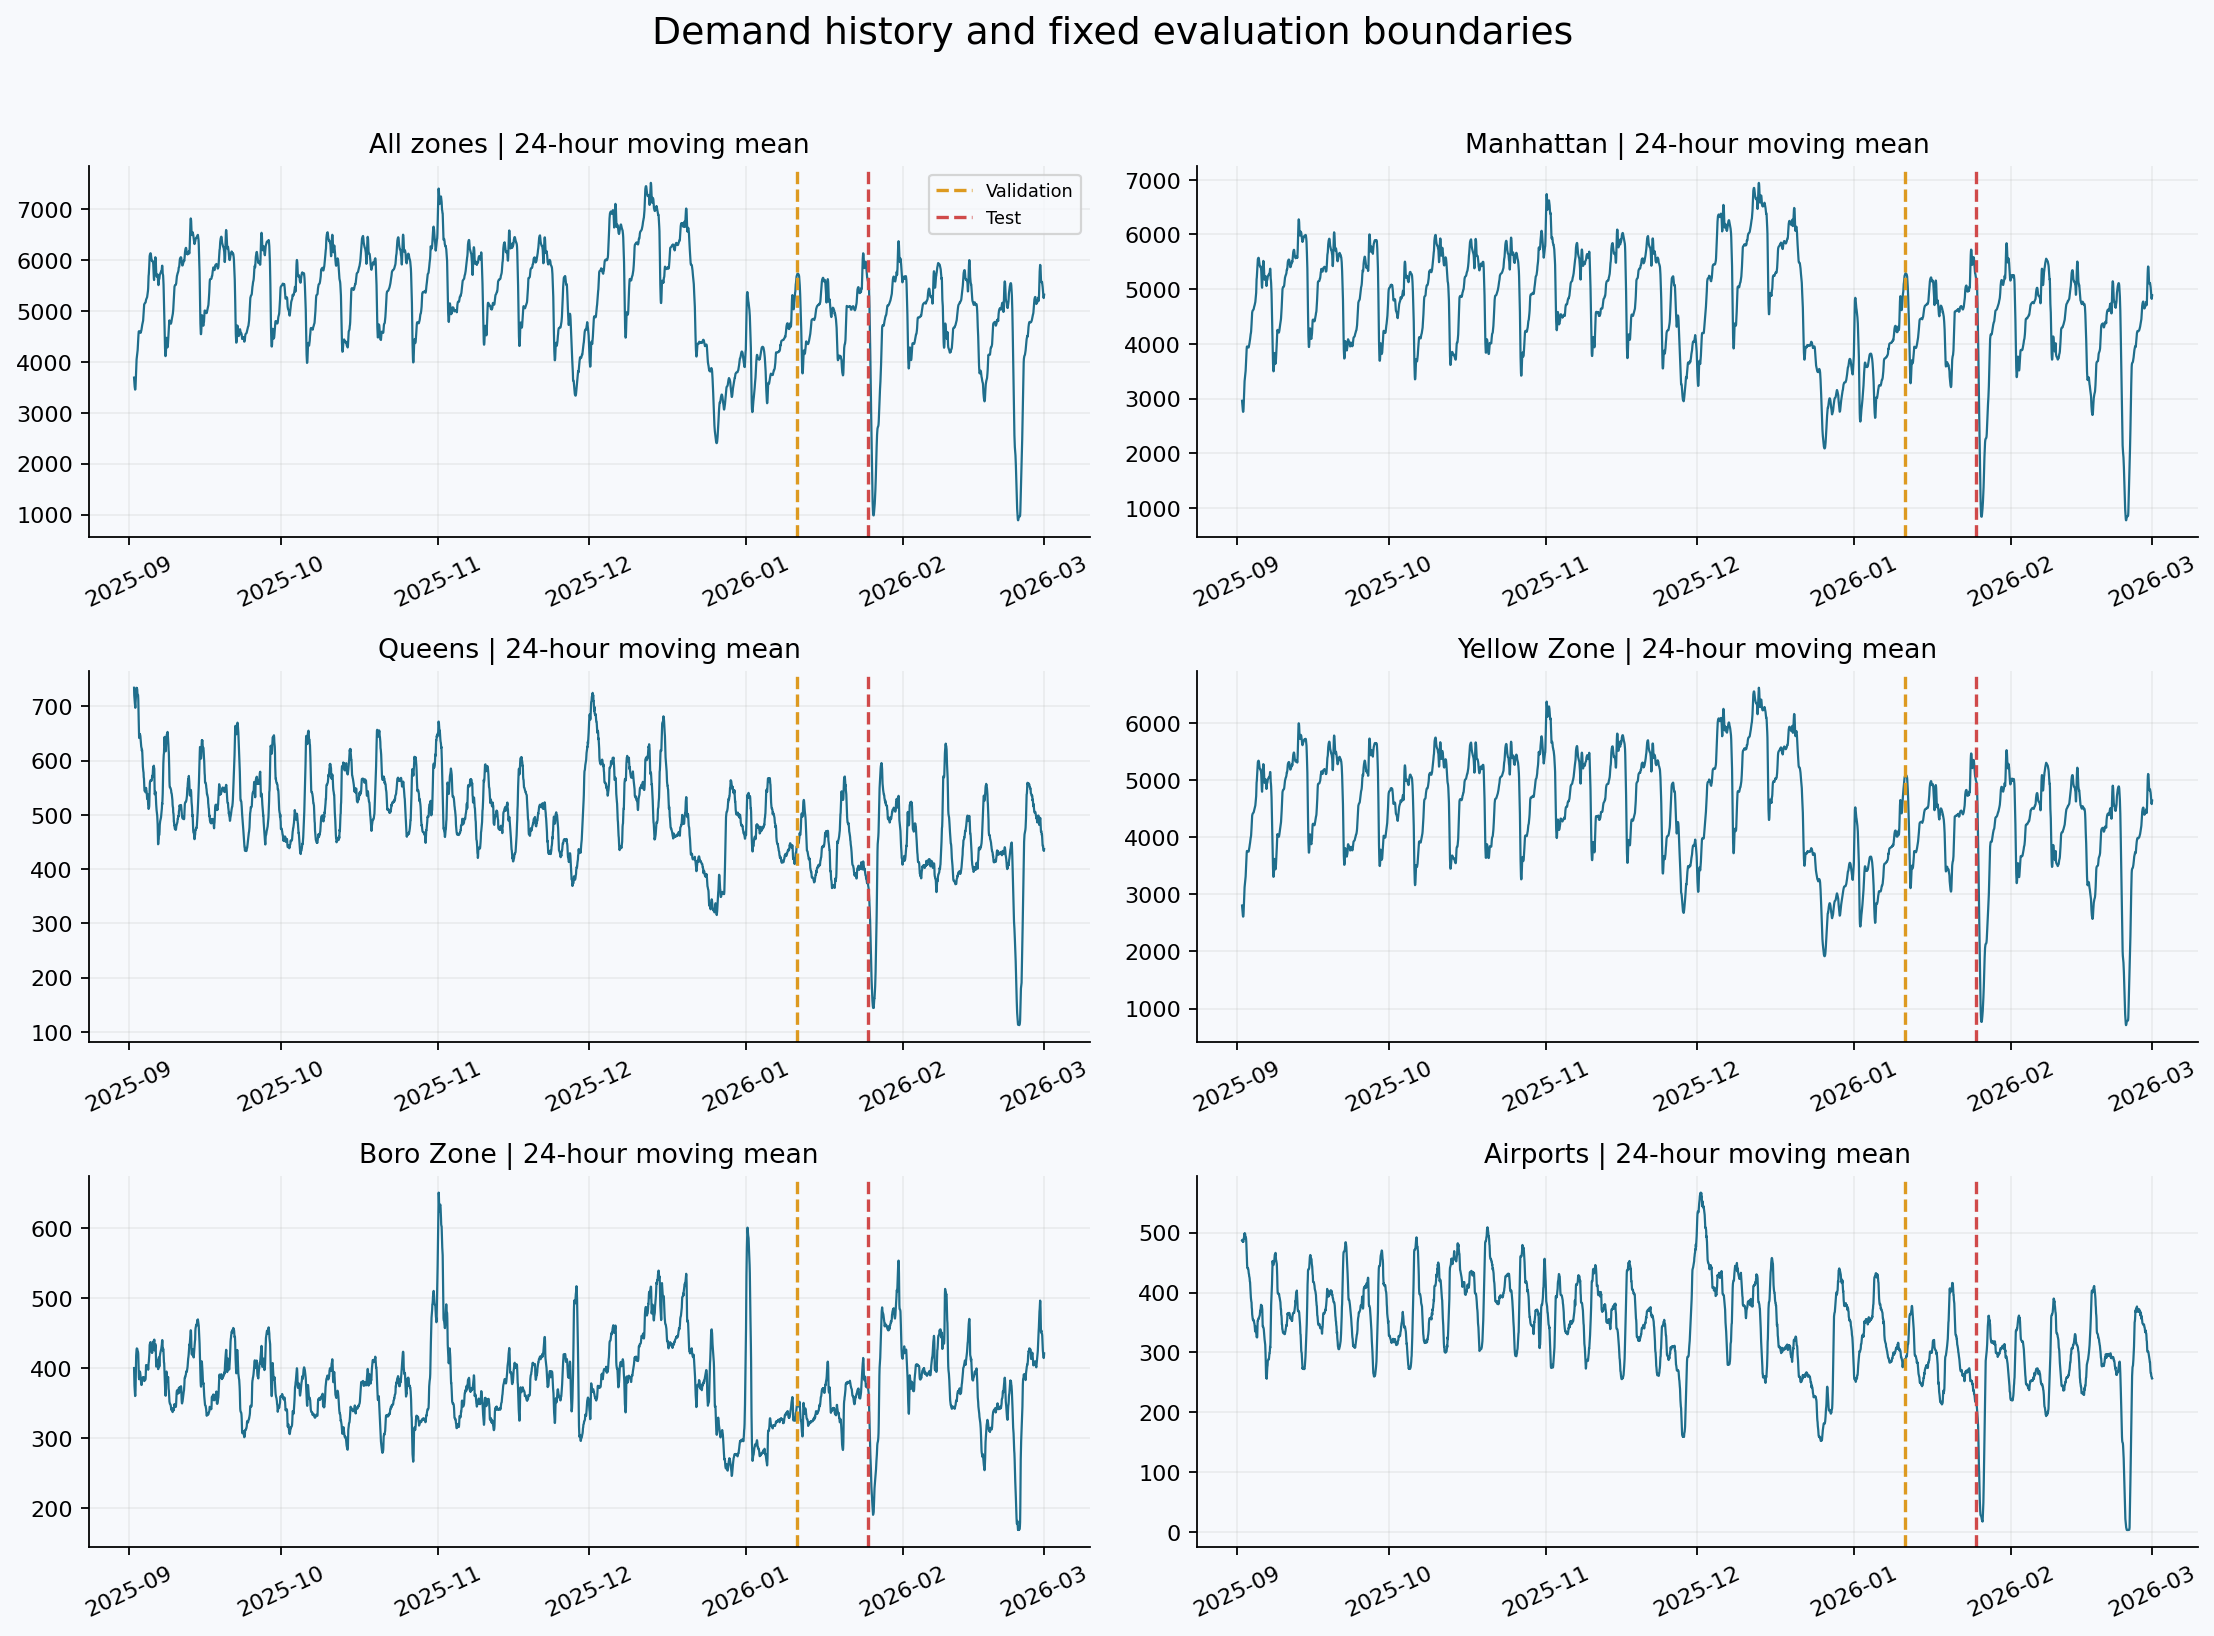

In [2]:
display(table('input_checks.csv'))
display(table('input_manifest.csv')[['path','rows','columns']])
figure('01_series_overview.png')

## Evaluation
Folds 1-4 select models by pooled MAE; folds 5-6 calibrate uncertainty.
The hourly holdout is 25 January 04:00 through 28 February 23:00 (836 hours).
Forecasts are issued every 24 or 168 hours. No demand within a forecast block is
available until the next origin. Daily evaluation covers complete dates and begins
four hours earlier. The weekly-selected model is evaluated at both hourly schedules.
Future weather, target columns, Fourier features, and event labels are not model inputs.

## Seasonal analysis without the teammate's decomposition
The descriptive log-demand decomposition uses a centered 337-hour rolling-median trend,
median detrended demand by hour, then median remaining demand by hour-of-week.
The residual closes the additive identity. This is **not MSTL** and none of these
components feeds a forecaster. Only training data is analyzed.
Component strength is max(0, 1 - Var(residual)/Var(residual + component)); it is not forecast accuracy.

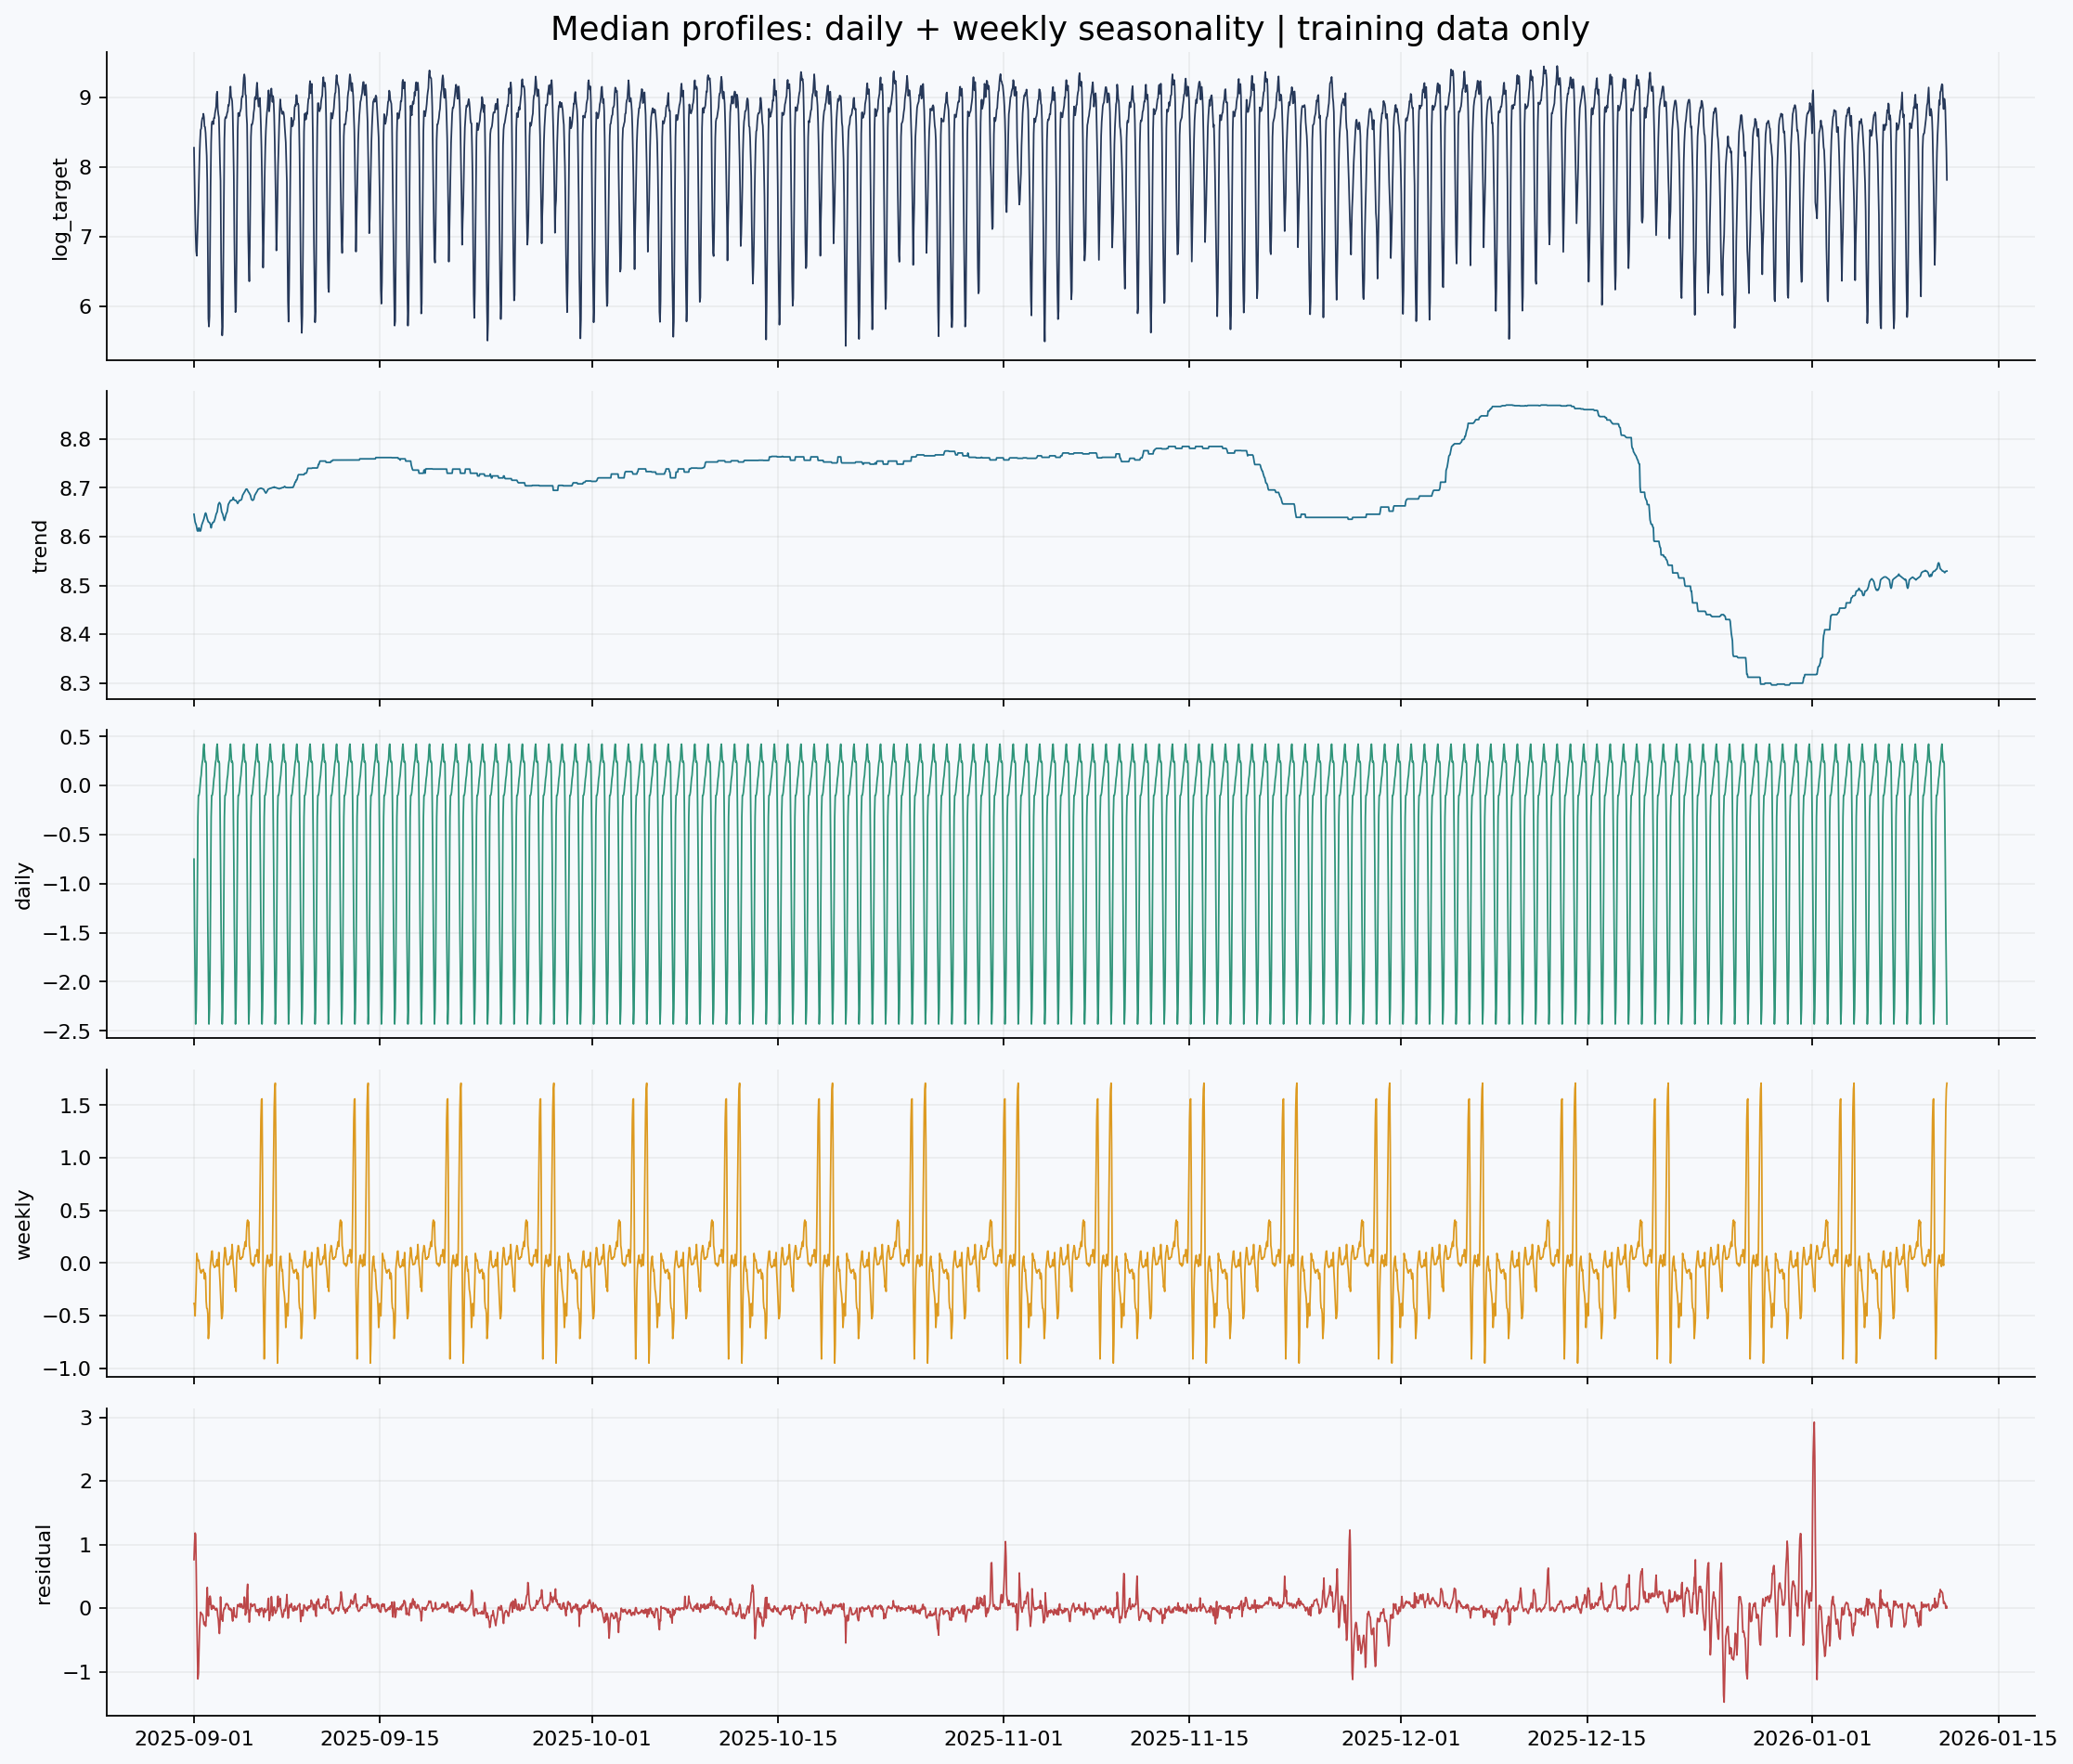

component,daily,trend,weekly
series_id,,,
Airports,0.897,0.037,0.193
All zones,0.941,0.262,0.757
Boro Zone,0.862,0.100,0.468
Manhattan,0.939,0.276,0.770
Queens,0.888,0.041,0.326
Yellow Zone,0.938,0.280,0.770


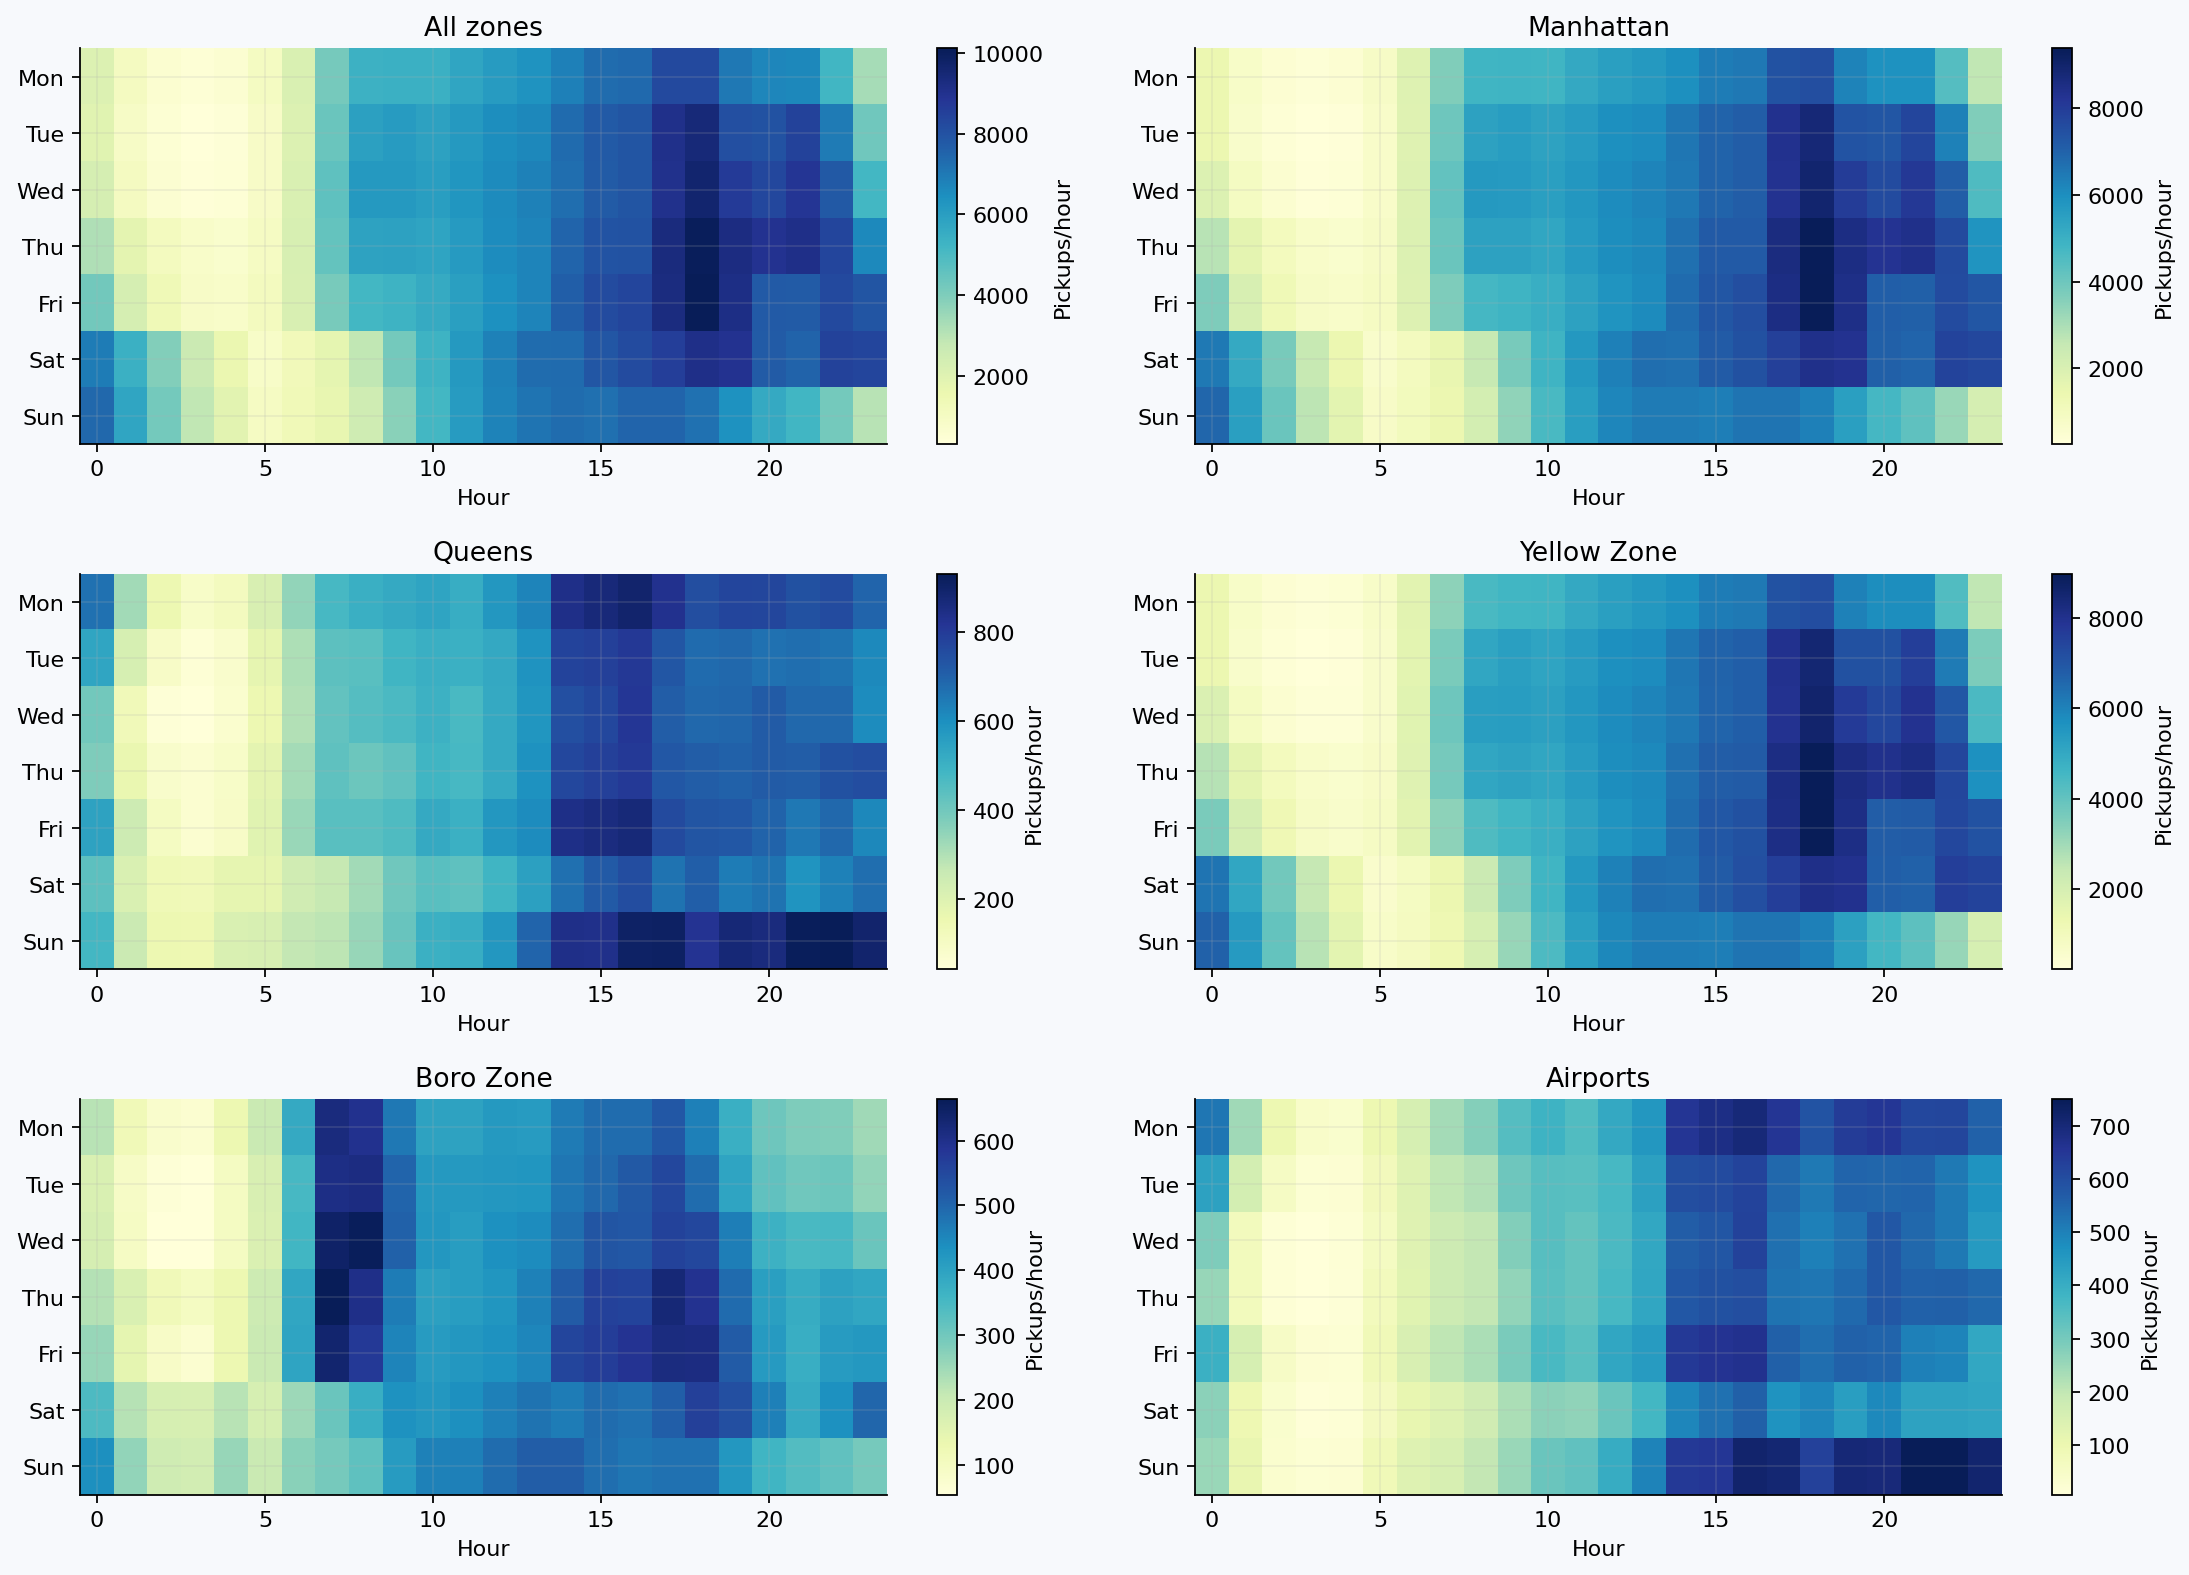

In [3]:
figure('02_seasonal_profile_decomposition.png')
display(table('seasonal_strength.csv').pivot(index='series_id',columns='component',values='strength'))
figure('04_weekly_heatmaps.png')

## Dependence and stationarity
ACF, PACF and a spectral periodogram describe temporal dependence.
ADF tests a unit-root null; KPSS tests a stationary-level null. The saved table includes
warnings for bounded KPSS p-values. Passing a differenced-series test does not guarantee
good forecasting. Spectral analysis does not mean Fourier regressors are fitted.

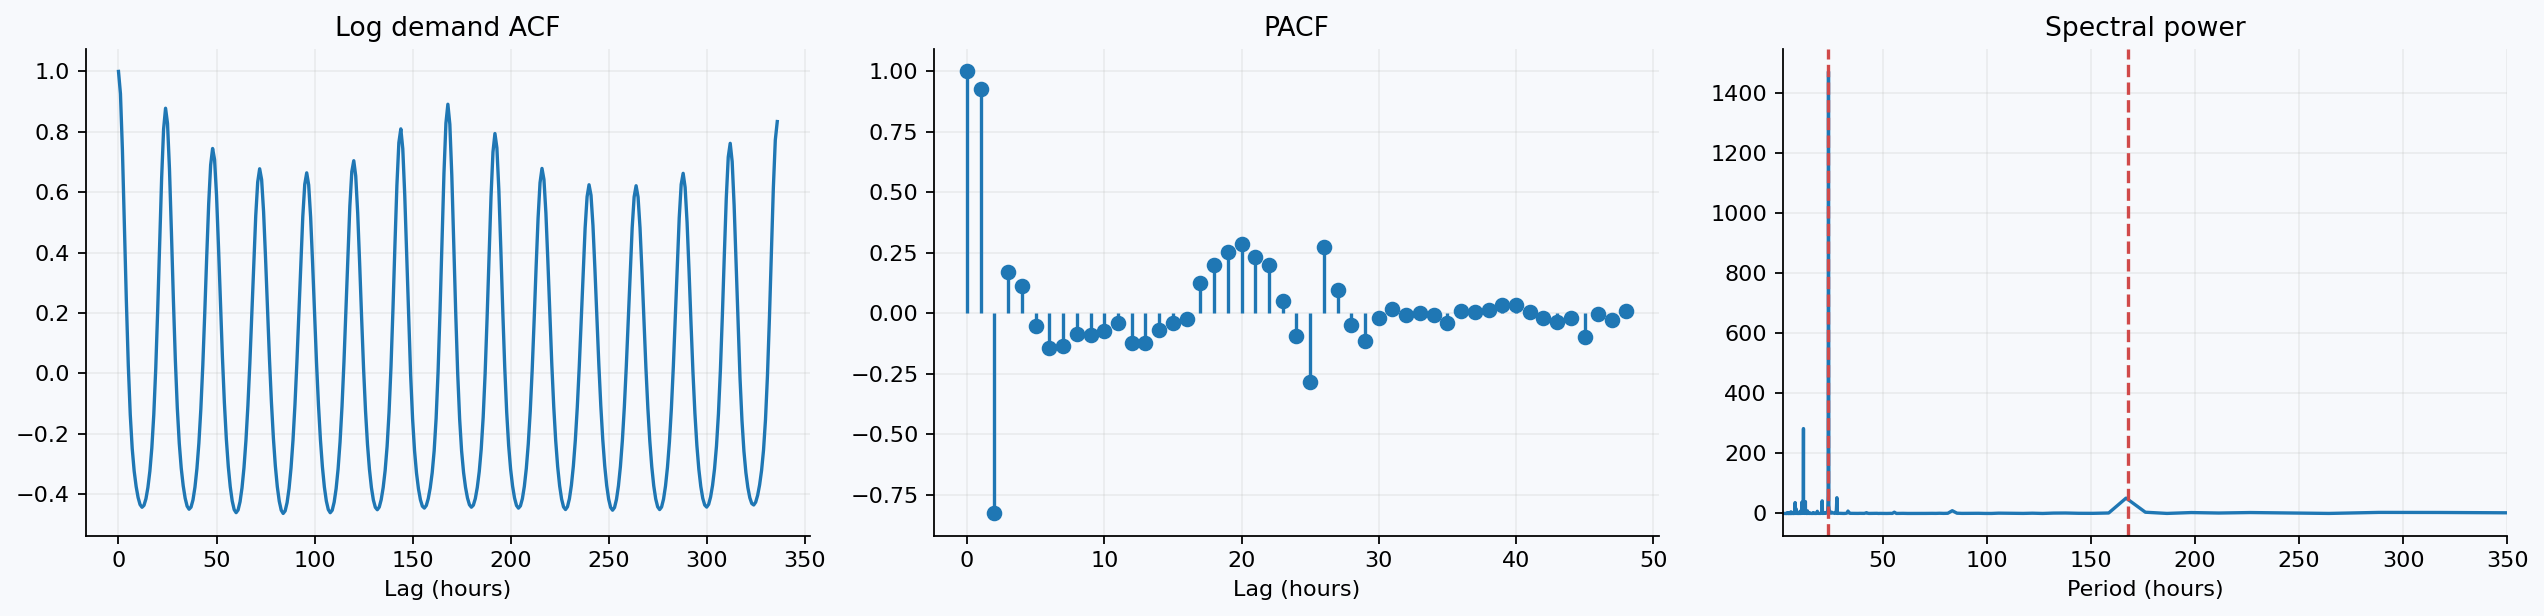

,series_id,transformation,n,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,kpss_lags,both_support_stationarity
0,All zones,level,3172,-5.412,0.000,24,0.755,0.010,27,False
1,All zones,log1p,3172,-6.660,0.000,24,0.646,0.018,23,False
2,All zones,log_diff_24,3148,-9.464,0.000,24,0.017,0.100,21,True
3,All zones,log_diff_168,3004,-4.214,0.001,24,0.222,0.100,27,True
4,All zones,log_diff_168_1,3003,-17.510,0.000,23,0.027,0.100,96,True


In [4]:
figure('03_dependence_spectrum.png')
display(table('stationarity.csv').query("series_id == 'All zones'").drop(columns='warnings'))

## Forecast methods and exact settings
| Method | Definition |
|---|---|
| Seasonal naive | Repeat the final observed 24/168-hour or 7-day cycle |
| Four-week mean | Average four matching weekly cycles |
| Adaptive seasonal | Four-week profile x [1 + (recent-level ratio - 1) exp(-lead/48)] |
| Daily adaptive seasonal | Same construction with daily units and exp(-lead/2) |
| TSB | Smoothed demand-occurrence probability x smoothed positive demand size |

Hourly adaptation compares the last observed 24-hour mean against matching prior weekly
windows. Daily adaptation compares the last day. Ratios add one to numerator/denominator
and are clipped to 0.5-1.5. TSB uses alpha=0.10 for positive size and beta=0.05 for occurrence.
TSB uses exponential updates internally, but is not an MSTL-plus-ETS forecasting pipeline.
These are existing method families adapted to this project, not a claimed new algorithm.

,series_id,model,eligible,selection_MAE
23,Airports,adaptive_week,True,78.562
22,Airports,mean_4weeks,True,82.298
20,Airports,naive_24,True,83.222
21,Airports,naive_168,True,99.384
3,All zones,adaptive_week,True,"1,133.393"
1,All zones,naive_168,True,"1,269.719"
2,All zones,mean_4weeks,True,"1,368.600"
0,All zones,naive_24,True,"1,473.692"
19,Boro Zone,adaptive_week,True,86.864
18,Boro Zone,mean_4weeks,True,104.209


,series_id,model,eligible,selection_MAE
17,Airports,adaptive_week_daily,True,"1,276.981"
16,Airports,mean_4weeks_daily,True,"1,399.732"
15,Airports,naive_7,True,"1,849.786"
2,All zones,adaptive_week_daily,True,"23,815.095"
0,All zones,naive_7,True,"24,991.821"
1,All zones,mean_4weeks_daily,True,"29,752.964"
14,Boro Zone,adaptive_week_daily,True,"1,430.537"
12,Boro Zone,naive_7,True,"1,713.107"
13,Boro Zone,mean_4weeks_daily,True,"1,813.875"
5,Manhattan,adaptive_week_daily,True,"23,014.842"


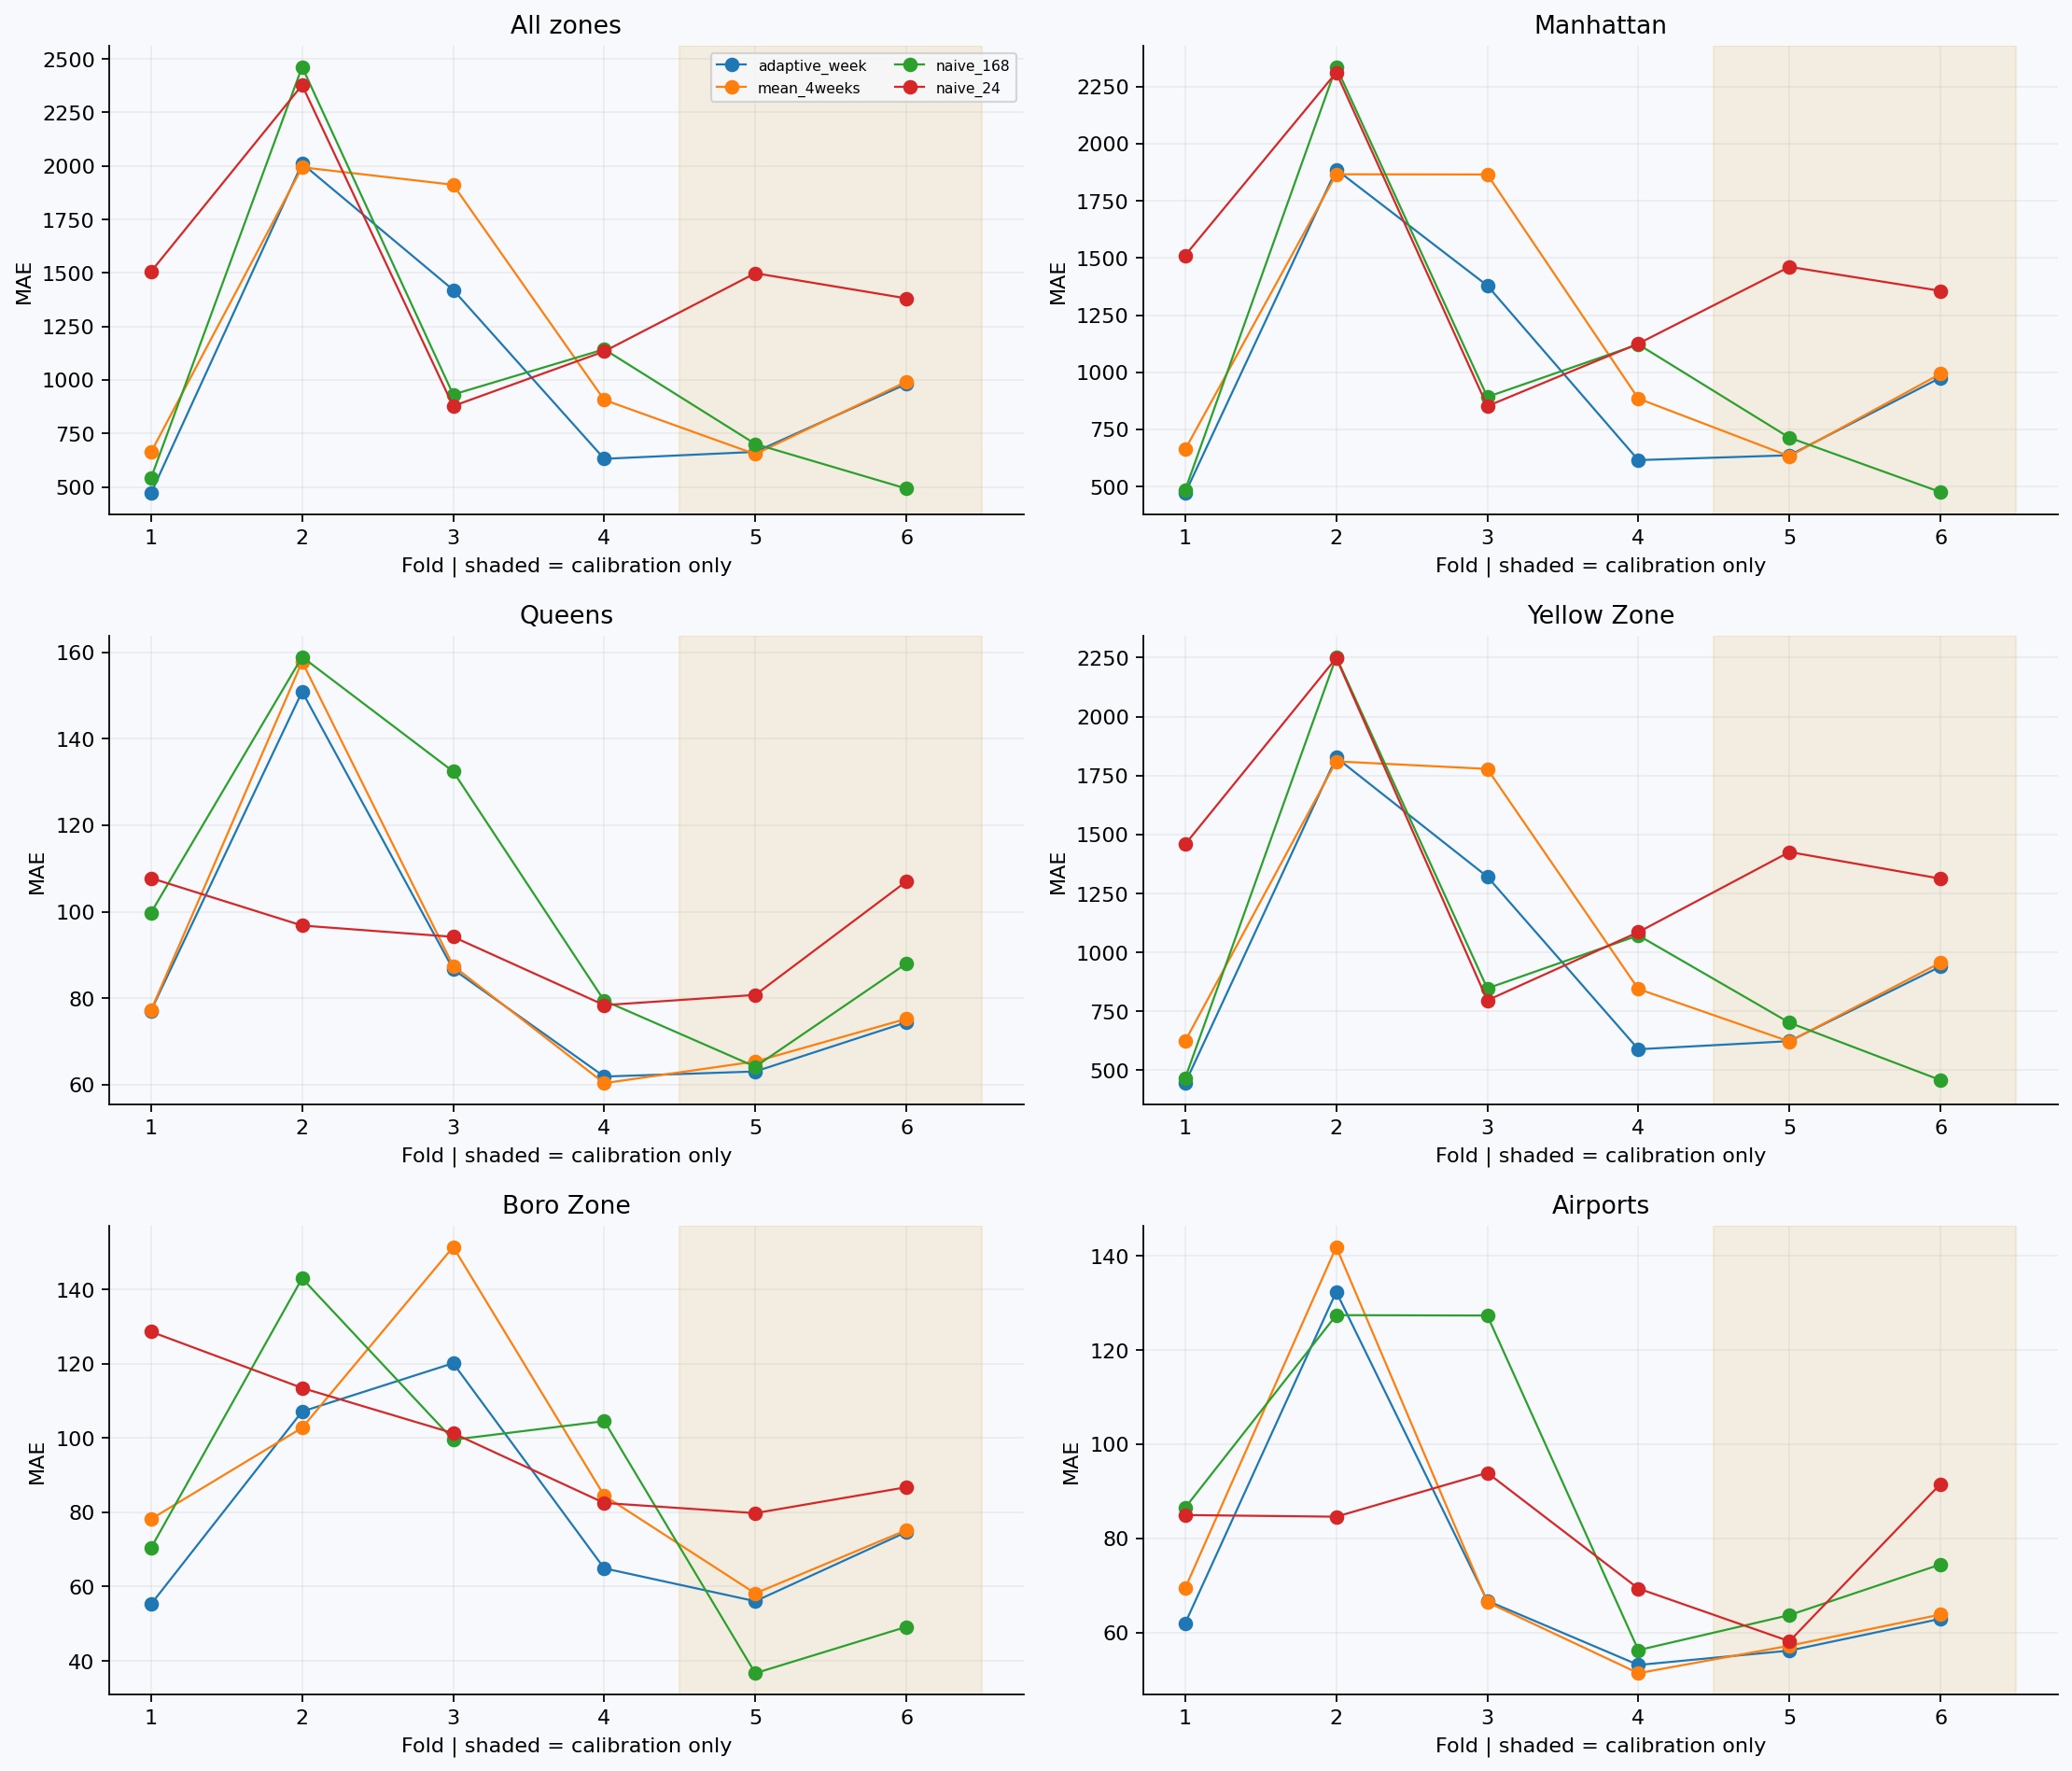

In [5]:
display(table('hourly_selection.csv').sort_values(['series_id','selection_MAE']))
display(table('daily_selection.csv').sort_values(['series_id','selection_MAE']))
figure('05_rolling_validation.png')

## Independent aggregate results
MAE and RMSE are pickups/hour at the specified geography. WAPE is a percentage.
MASE uses pre-test weekly differences; positive bias means overprediction.
A weekly naive baseline is evaluated under exactly the same forecast origins.

,series_id,model,schedule,selected,n,MAE,RMSE,WAPE,bias,R2,MASE
0,Airports,adaptive_week,24,True,836,71.205,117.861,26.068,9.037,0.638,0.867
1,Airports,adaptive_week,168,True,836,72.725,126.336,26.624,8.126,0.585,0.885
2,Airports,naive_168,24,False,836,89.574,151.763,32.792,9.316,0.400,1.090
3,Airports,naive_168,168,False,836,89.574,151.763,32.792,9.316,0.400,1.090
4,All zones,adaptive_week,24,True,836,678.206,"1,091.713",14.586,73.881,0.853,0.893
5,All zones,adaptive_week,168,True,836,678.607,"1,134.605",14.595,186.254,0.841,0.893
6,All zones,naive_168,24,False,836,777.712,"1,292.180",16.727,180.977,0.794,1.024
7,All zones,naive_168,168,False,836,777.712,"1,292.180",16.727,180.977,0.794,1.024
8,Boro Zone,adaptive_week,24,True,836,71.496,107.390,18.666,-1.742,0.734,1.017
9,Boro Zone,adaptive_week,168,True,836,74.334,112.617,19.407,-1.390,0.707,1.057


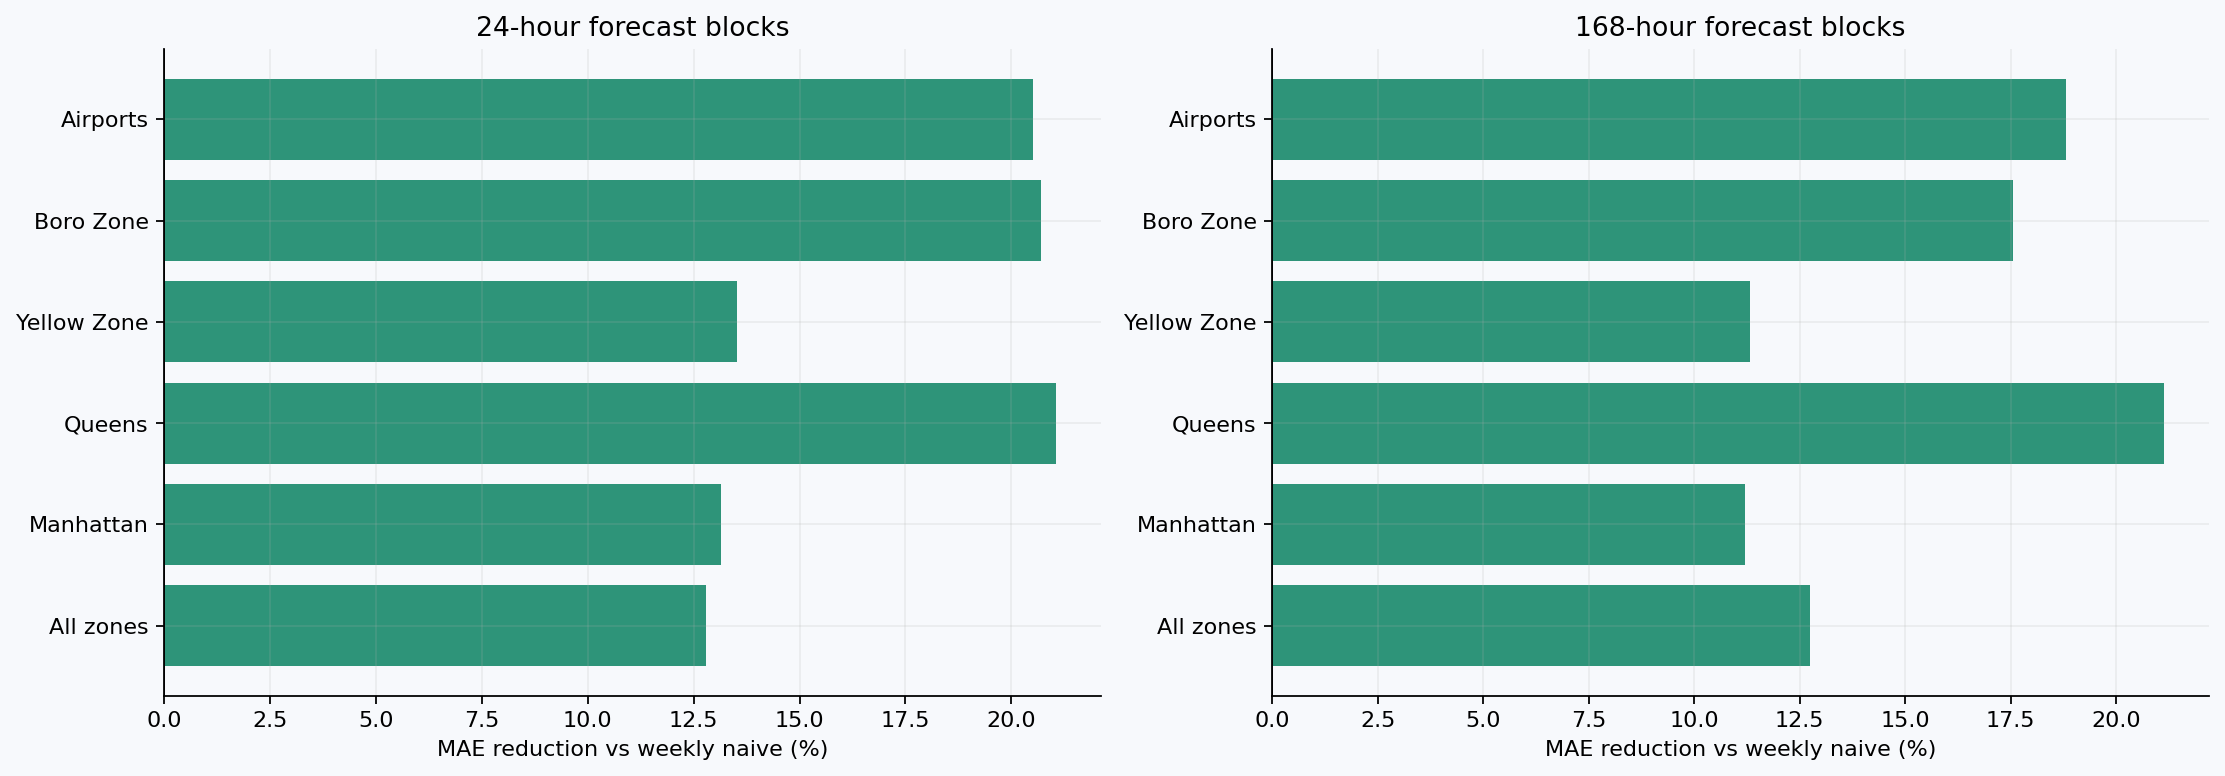

,series_id,schedule,MAE_improvement,lower_95,upper_95,origin_blocks,note
0,All zones,24,99.506,-56.813,294.352,35,Exploratory; adjacent origins can remain depen...
1,All zones,168,99.105,-118.510,349.265,5,Exploratory; adjacent origins can remain depen...
2,Manhattan,24,93.834,-44.209,260.037,35,Exploratory; adjacent origins can remain depen...
3,Manhattan,168,79.966,-136.314,312.527,5,Exploratory; adjacent origins can remain depen...
4,Queens,24,24.867,3.619,47.261,35,Exploratory; adjacent origins can remain depen...
5,Queens,168,24.957,-1.373,54.810,5,Exploratory; adjacent origins can remain depen...
6,Yellow Zone,24,91.861,-47.574,251.106,35,Exploratory; adjacent origins can remain depen...
7,Yellow Zone,168,76.860,-114.905,275.611,5,Exploratory; adjacent origins can remain depen...
8,Boro Zone,24,18.676,5.489,32.096,35,Exploratory; adjacent origins can remain depen...
9,Boro Zone,168,15.838,-5.382,38.595,5,Exploratory; adjacent origins can remain depen...


In [6]:
display(table('hourly_test_metrics.csv'))
figure('06_holdout_improvement.png')
display(table('paired_block_bootstrap.csv'))

## Empirical intervals
Two pre-test weeks provide absolute-error quantiles. Day-ahead lead bins are 1-6,
7-12 and 13-24; weekly bins are 1-24, 25-72 and 73-168. Lower bounds are clipped at zero.
Finite-sample quantiles do not remove serial dependence or distribution shift.
Coverage, width and interval scores must be considered together. Bootstrap comparisons
resample whole origins; only five weekly blocks make uncertainty estimates exploratory.

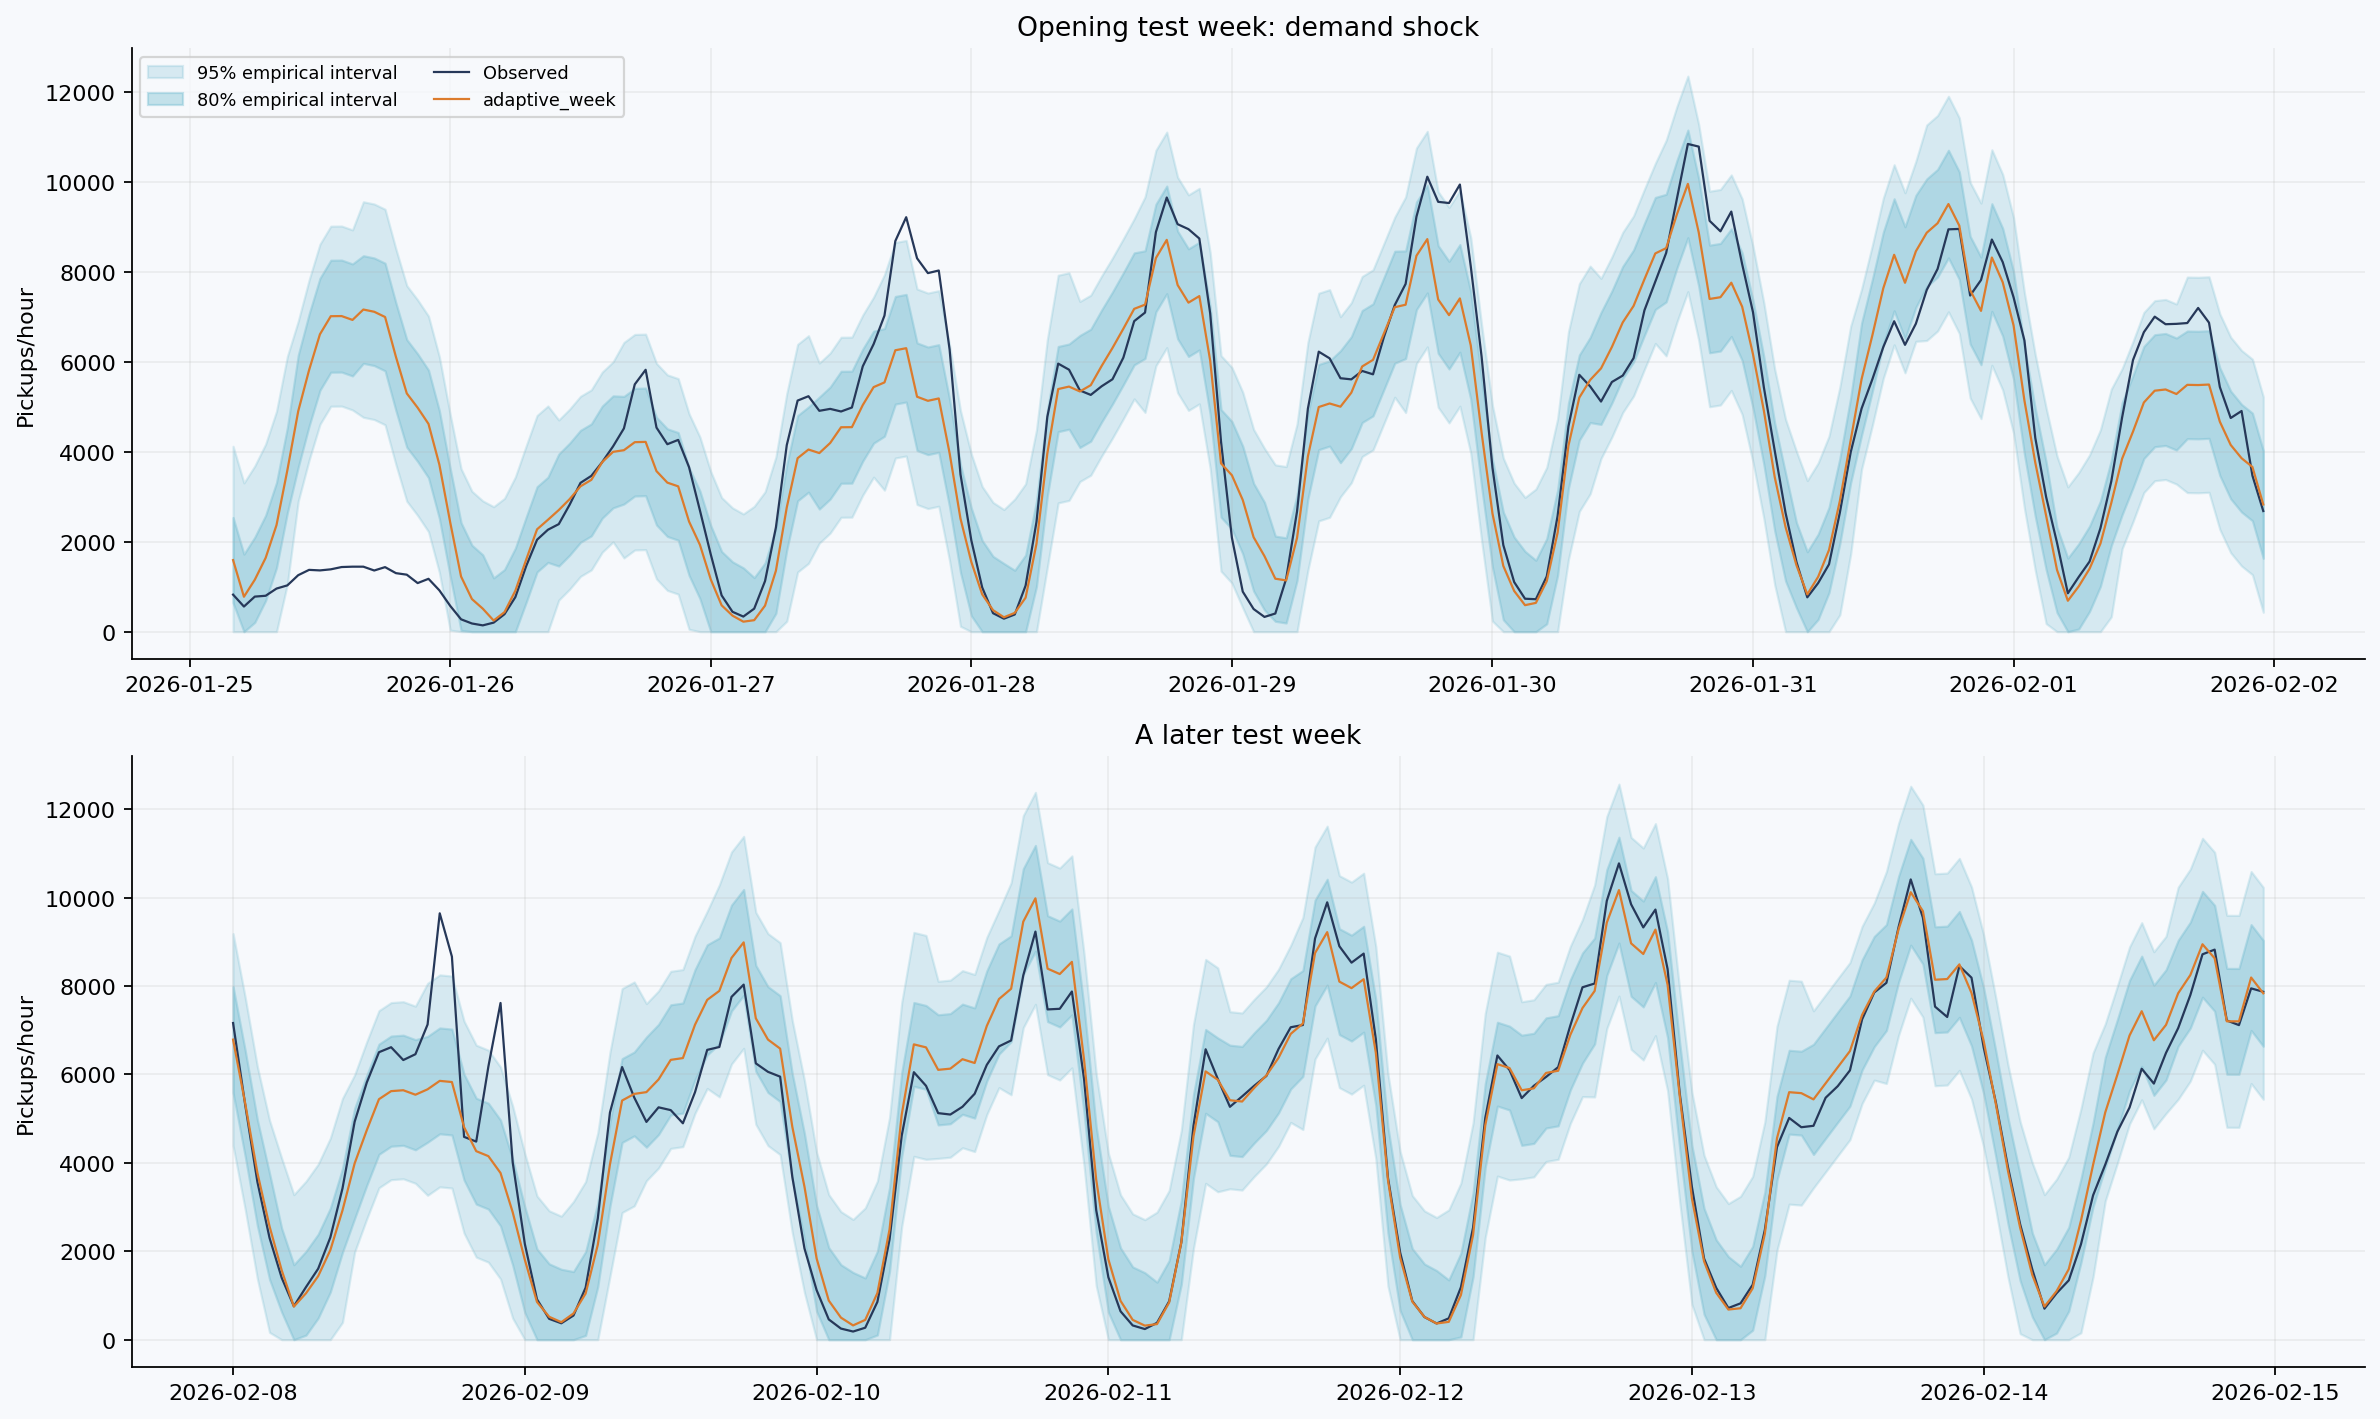

,series_id,schedule,nominal_coverage,coverage,mean_width,interval_score
0,Airports,24,0.800,0.733,166.065,417.194
1,Airports,168,0.800,0.806,188.892,438.568
2,All zones,24,0.800,0.837,"2,224.118","3,862.862"
3,All zones,168,0.800,0.818,"2,557.449","4,723.082"
4,Boro Zone,24,0.800,0.760,207.535,430.996
5,Boro Zone,168,0.800,0.720,201.778,458.218
6,Manhattan,24,0.800,0.848,"2,149.598","3,508.285"
7,Manhattan,168,0.800,0.827,"2,535.253","4,335.481"
8,Queens,24,0.800,0.731,221.966,530.714
9,Queens,168,0.800,0.732,213.917,530.890


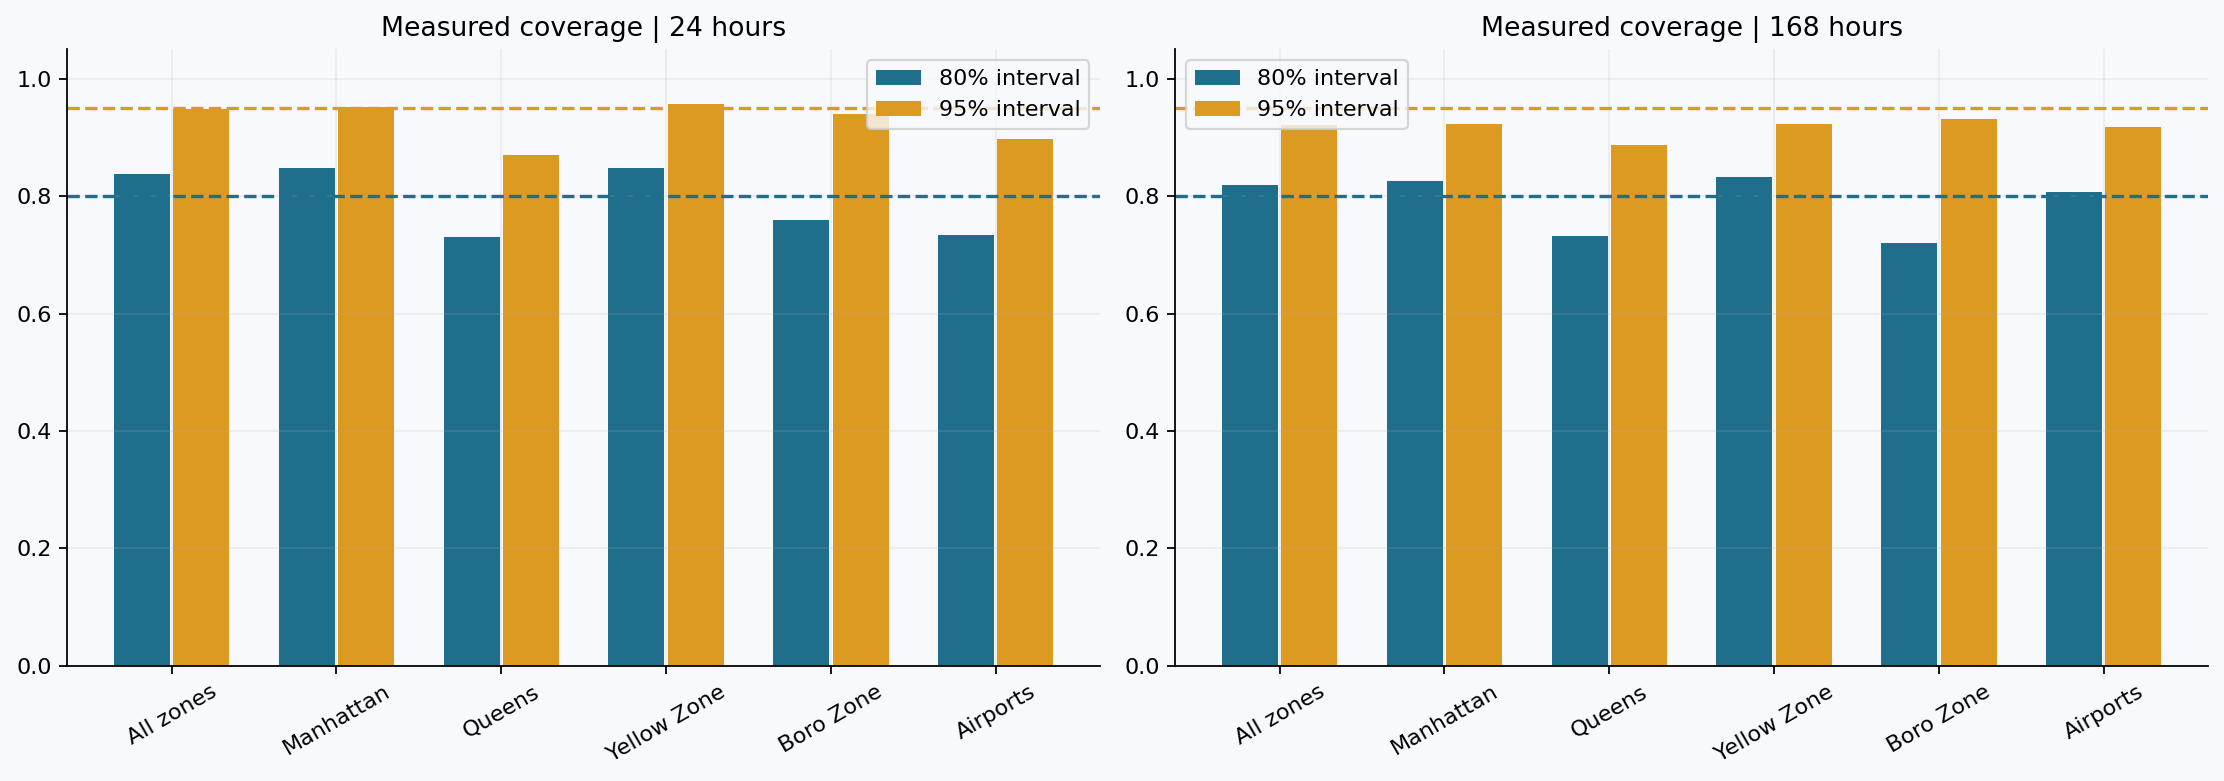

In [7]:
figure('07_forecast_intervals.png')
display(table('interval_metrics.csv'))
figure('09_interval_coverage.png')

## Errors, storms, and peak hours
Snow flags are retrospective diagnostic labels and do not enter forecasts.
Ljung-Box assesses multi-step forecast errors, not independent one-step innovations.
The first test date contains only 20 scored hours. Event comparisons are not causal effects.

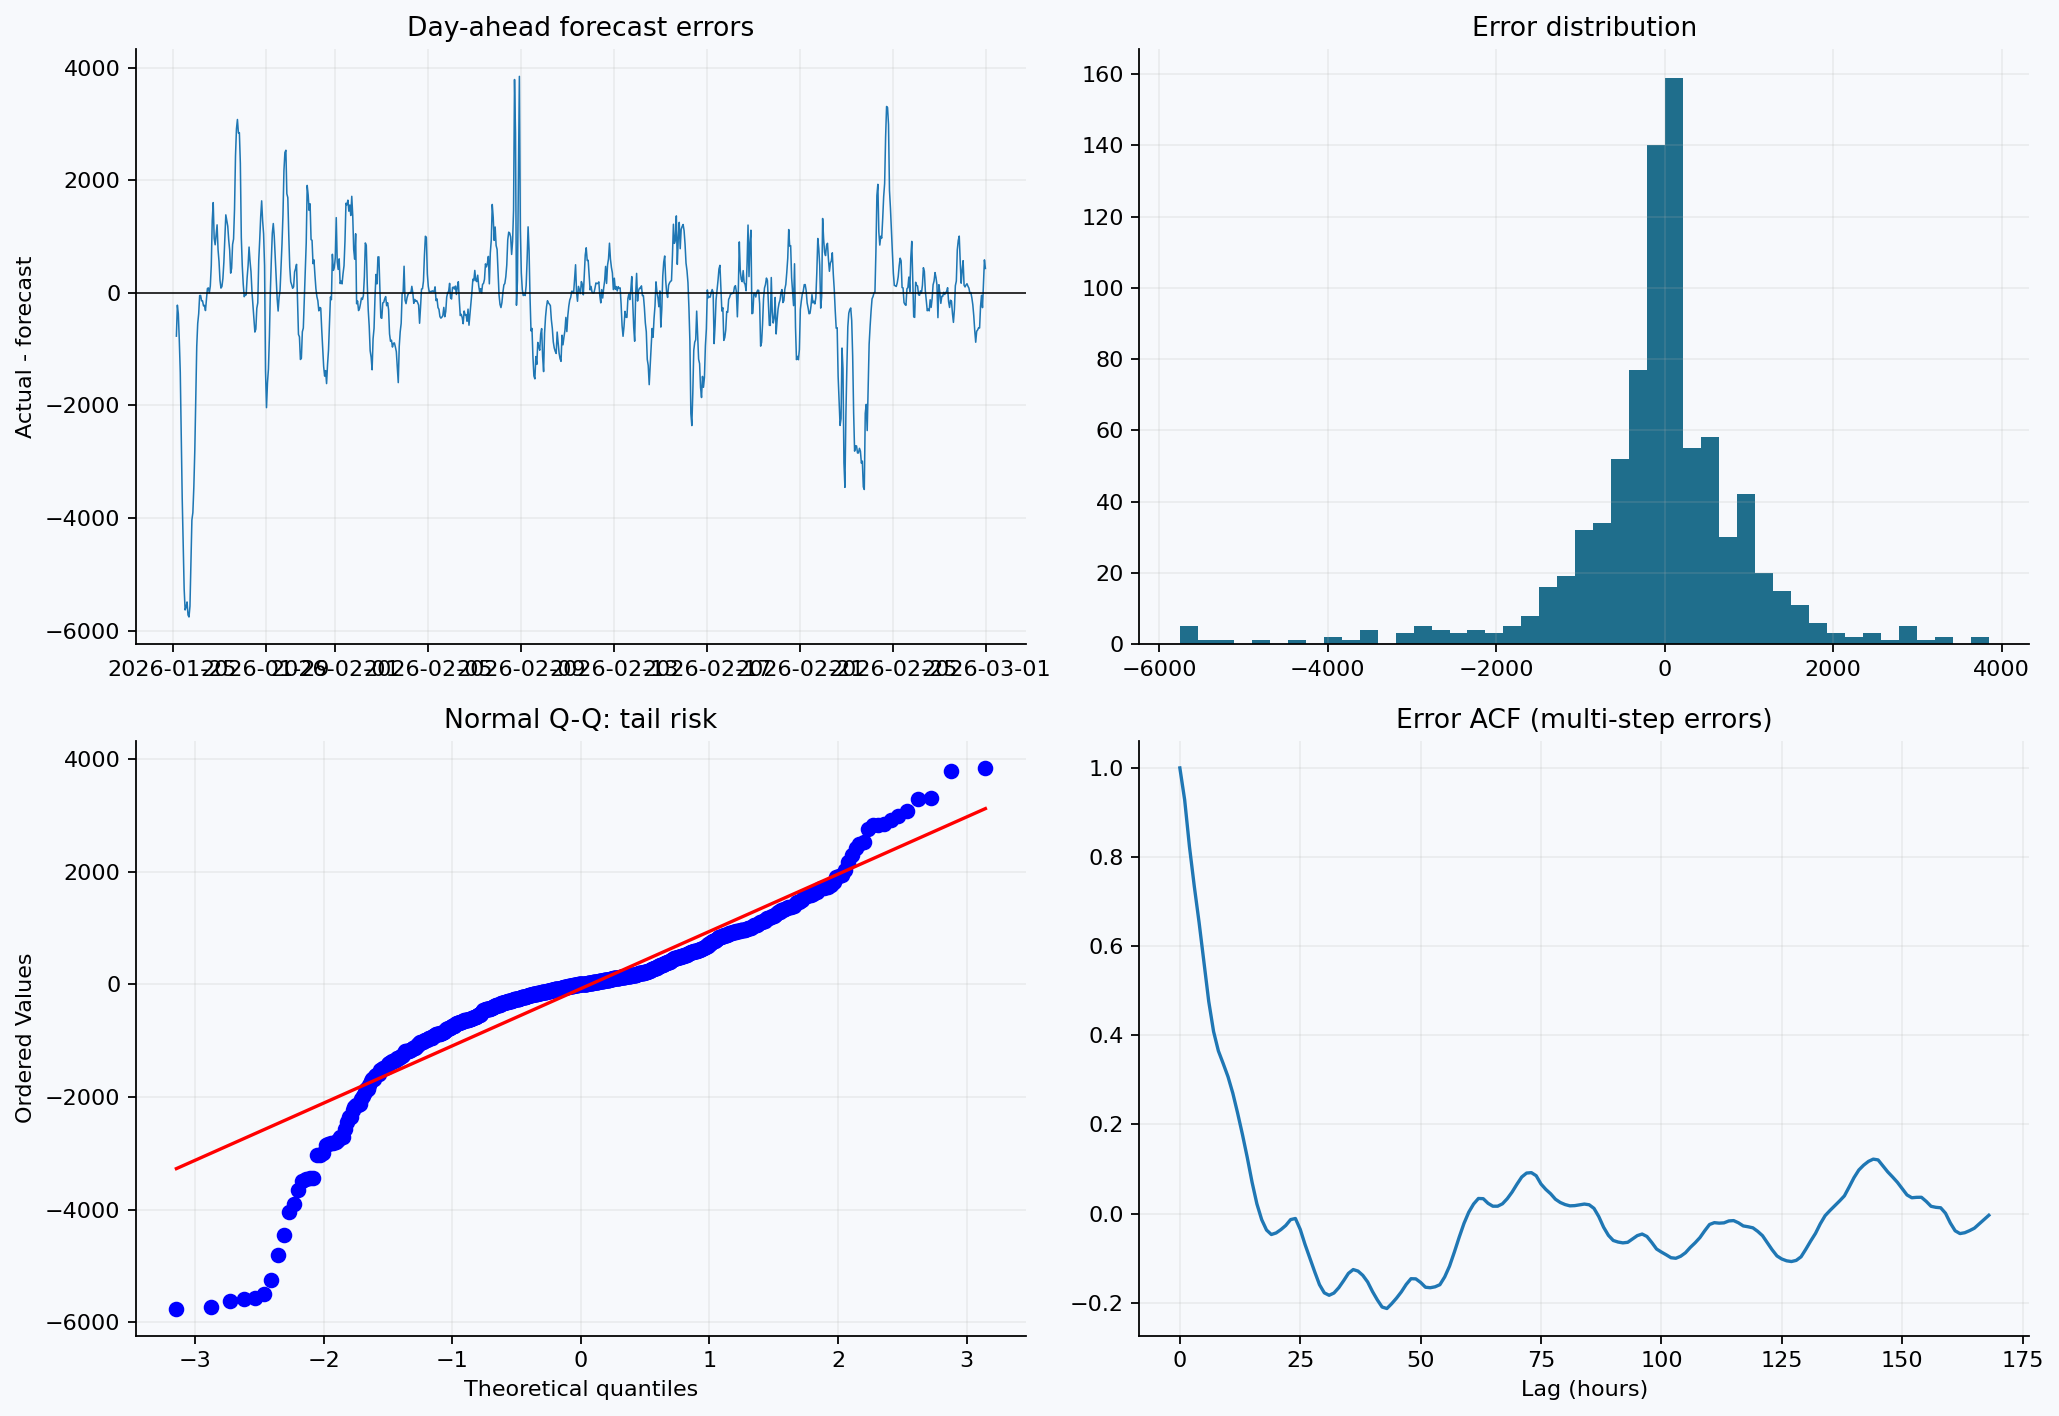

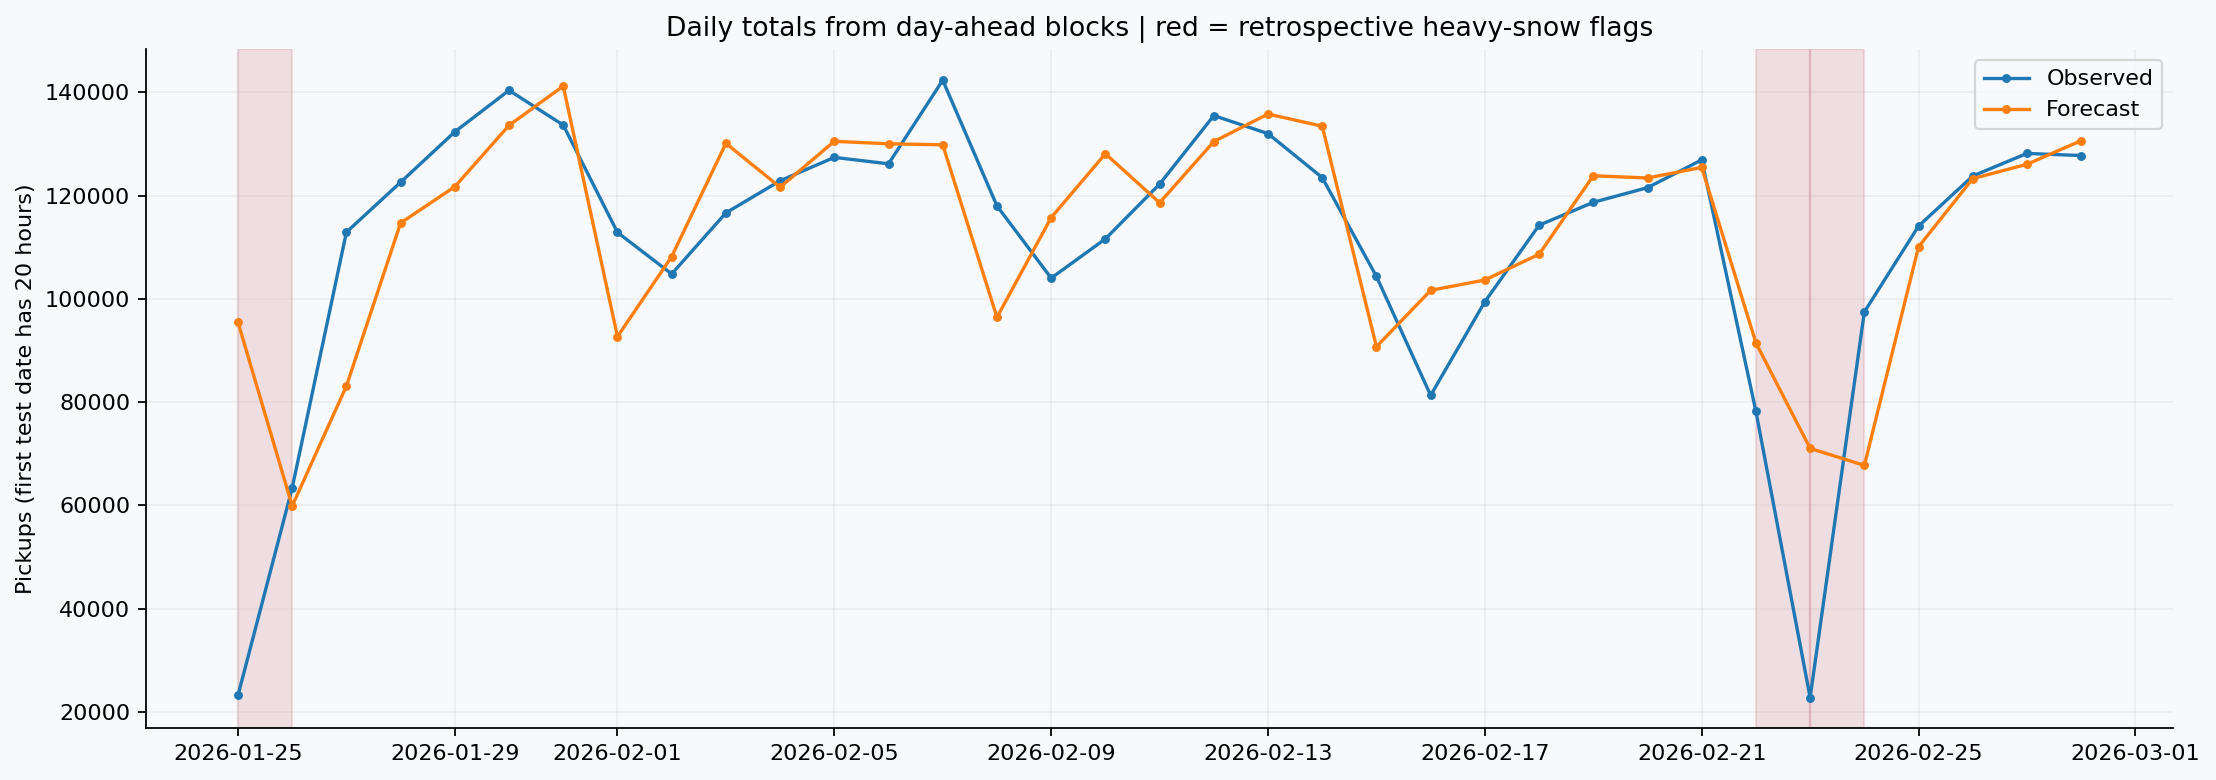

,series_id,schedule,dimension,value,n,MAE,RMSE,WAPE,bias,R2
56,All zones,24,is_heavy_snow_day,False,768,545.156,796.488,11.127,-93.784,0.919
57,All zones,24,is_heavy_snow_day,True,68,"2,180.888","2,736.360",119.419,"1,967.514",-2.318
84,All zones,168,is_heavy_snow_day,False,768,525.492,780.025,10.725,6.032,0.923
85,All zones,168,is_heavy_snow_day,True,68,"2,407.910","2,992.455",131.850,"2,221.701",-2.968


,series_id,schedule,date,actual,prediction,hourly_MAE,hours,total_error
0,All zones,24,2026-01-25,23207,"95,477.372","3,613.519",20,"72,270.372"
9,All zones,24,2026-02-23,22783,"71,032.026","2,010.376",24,"48,249.026"
15,All zones,24,2026-02-24,97466,"67,748.977","1,329.218",24,"-29,717.023"
16,All zones,24,2026-01-27,112903,"83,106.979","1,241.501",24,"-29,796.021"
17,All zones,24,2026-02-22,78195,"91,466.538","1,157.540",24,"13,271.538"
21,All zones,24,2026-02-16,81311,"101,639.263","1,103.231",24,"20,328.263"
24,All zones,24,2026-01-29,132344,"121,719.128","1,080.543",24,"-10,624.872"
32,All zones,24,2026-02-08,118001,"96,425.086",973.057,24,"-21,575.914"
42,All zones,24,2026-02-01,112866,"92,684.289",869.116,24,"-20,181.711"
51,All zones,24,2026-02-09,104012,"115,729.223",744.636,24,"11,717.223"


schedule,24,168
series_id,,
Airports,0.520,0.412
All zones,0.775,0.800
Boro Zone,0.667,0.682
Manhattan,0.775,0.800
Queens,0.422,0.353
Yellow Zone,0.735,0.800


In [8]:
figure('08_residual_diagnostics.png')
figure('11_event_stress_test.png')
display(table('event_hour_errors.csv').query("series_id == 'All zones' and dimension == 'is_heavy_snow_day'"))
display(table('daily_error_totals.csv').query("series_id == 'All zones' and schedule == 24").head(10))
display(table('peak_hour_recall.csv').groupby(['series_id','schedule']).top_decile_recall.mean().unstack())

## All zones and coherent aggregation
Each zone selects a seasonal or TSB model using folds 1-4. All-zero and sparse zones
remain in evaluation. Summing zone forecasts yields exactly consistent borough and
service-area totals. This is bottom-up aggregation, not MinT or independent aggregate fitting.
Four selection folds limit how confidently we can select a separate model for every zone.

model,adaptive_week,mean_4weeks,naive_168,tsb
demand_pattern,,,,
erratic,29,2,4,0
intermittent,13,15,1,14
lumpy,4,5,0,1
no demand,0,0,2,0
smooth,42,3,1,2


,schedule,model,n,MAE,RMSE,WAPE,bias,R2
0,24,selected_zone_models,115368,7.820,20.302,23.210,0.637,0.913
1,24,naive_168,115368,9.307,24.057,27.625,1.311,0.878
2,168,selected_zone_models,115368,8.033,20.938,23.841,1.340,0.907
3,168,naive_168,115368,9.307,24.057,27.625,1.311,0.878


,schedule,group_type,group,baseline_MAE,n,MAE,RMSE,WAPE,bias,R2
0,24,Borough,Manhattan,15.590,57684,13.144,26.406,21.529,1.219,0.902
1,24,Borough,Queens,3.025,57684,2.496,11.272,39.412,0.055,0.853
2,24,volume_tier,High,25.837,32604,21.778,37.366,21.271,2.280,0.856
3,24,volume_tier,Low,2.184,28424,1.827,2.755,53.831,-0.099,0.522
4,24,volume_tier,Medium,7.505,20064,6.130,9.442,28.186,0.160,0.800
5,24,volume_tier,Sparse,0.575,32604,0.527,0.874,106.822,-0.038,0.140
6,24,volume_tier,Zero,0.000,1672,0.000,0.000,NaN,0.000,NaN
7,24,demand_pattern,erratic,16.301,29260,14.030,29.309,21.923,1.388,0.911
8,24,demand_pattern,intermittent,0.655,35948,0.593,0.993,98.221,-0.050,0.211
9,24,demand_pattern,lumpy,1.326,8360,1.137,1.826,72.265,-0.075,0.495


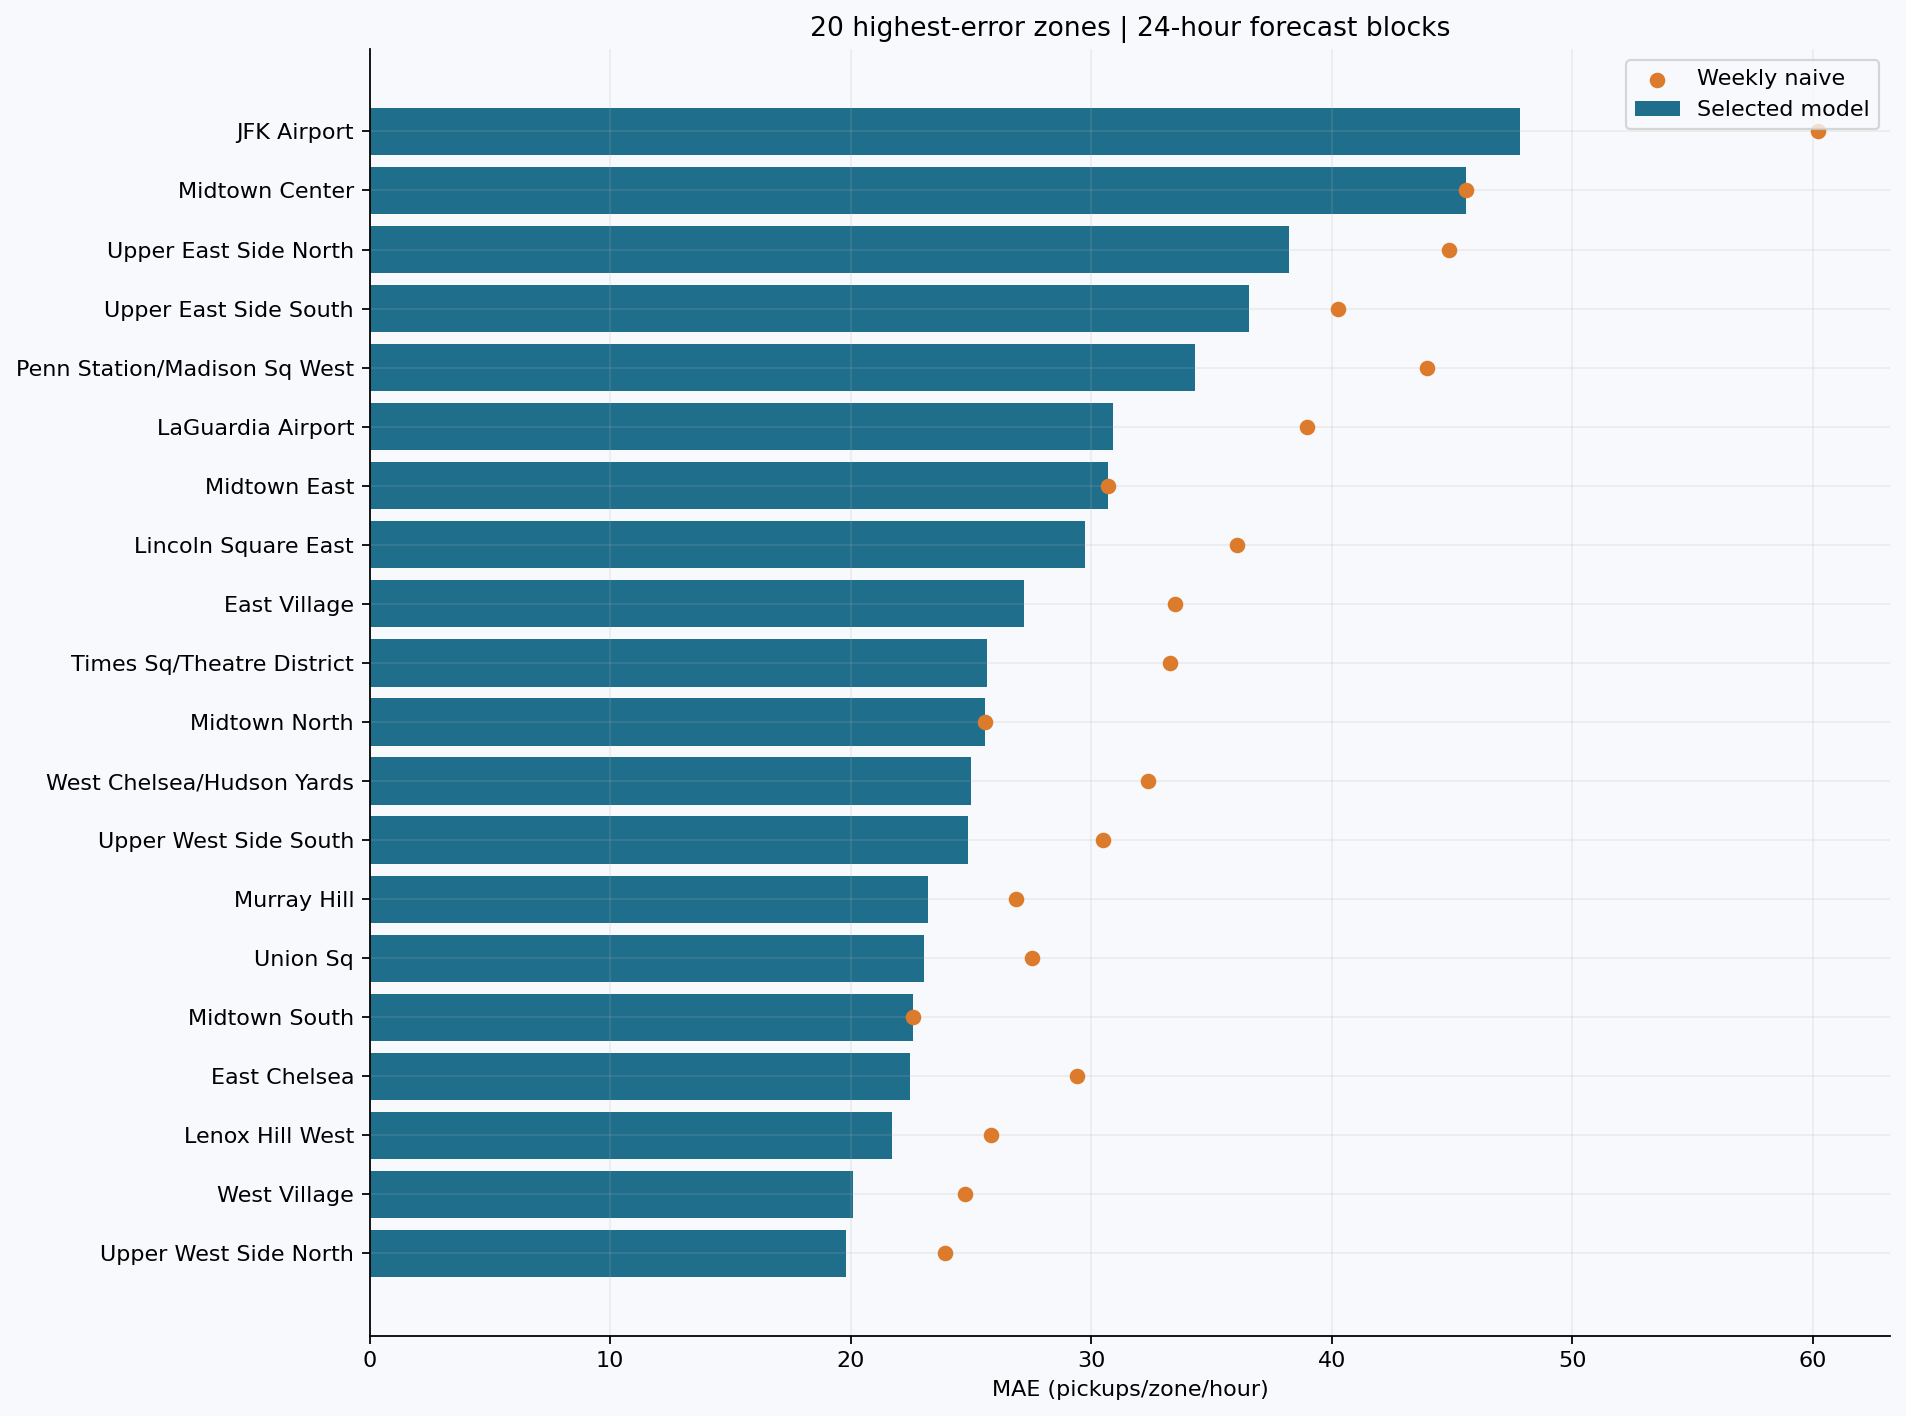

,series_id,schedule,n,MAE,RMSE,WAPE,bias,R2
0,Airports,24,836,71.215,117.831,26.071,8.926,0.639
1,Airports,168,836,72.810,126.530,26.655,8.086,0.583
2,All zones,24,836,649.371,"1,059.949",13.966,87.907,0.862
3,All zones,168,836,675.570,"1,128.520",14.530,184.871,0.843
4,Boro Zone,24,836,70.625,106.420,18.438,-5.930,0.738
5,Boro Zone,168,836,75.378,112.708,19.679,-2.537,0.707
6,Manhattan,24,836,591.709,968.234,14.046,84.095,0.868
7,Manhattan,168,836,630.344,"1,038.267",14.963,180.790,0.848
8,Queens,24,836,91.113,137.923,20.851,3.812,0.661
9,Queens,168,836,93.829,144.468,21.472,4.081,0.628


In [9]:
display(table('zone_selection.csv').groupby(['demand_pattern','model']).size().unstack(fill_value=0))
display(table('zone_test_metrics.csv'))
display(table('zone_group_metrics.csv'))
figure('10_zone_errors.png')
display(table('bottom_up_metrics.csv'))

## Main measured outcome
Day-ahead zone MAE is 7.8200 versus 9.3074 weekly naive (16.0% lower).
Summed demand MAE is 649.37 versus 777.71 (16.5% lower). This separate zone experiment
was already present before the teammate-driven scope revision and is unchanged.
Aggregate interval calibration uses errors of the summed forecasts, not summed zone bounds.
Marginal interval endpoints across geographic levels need not reconcile.

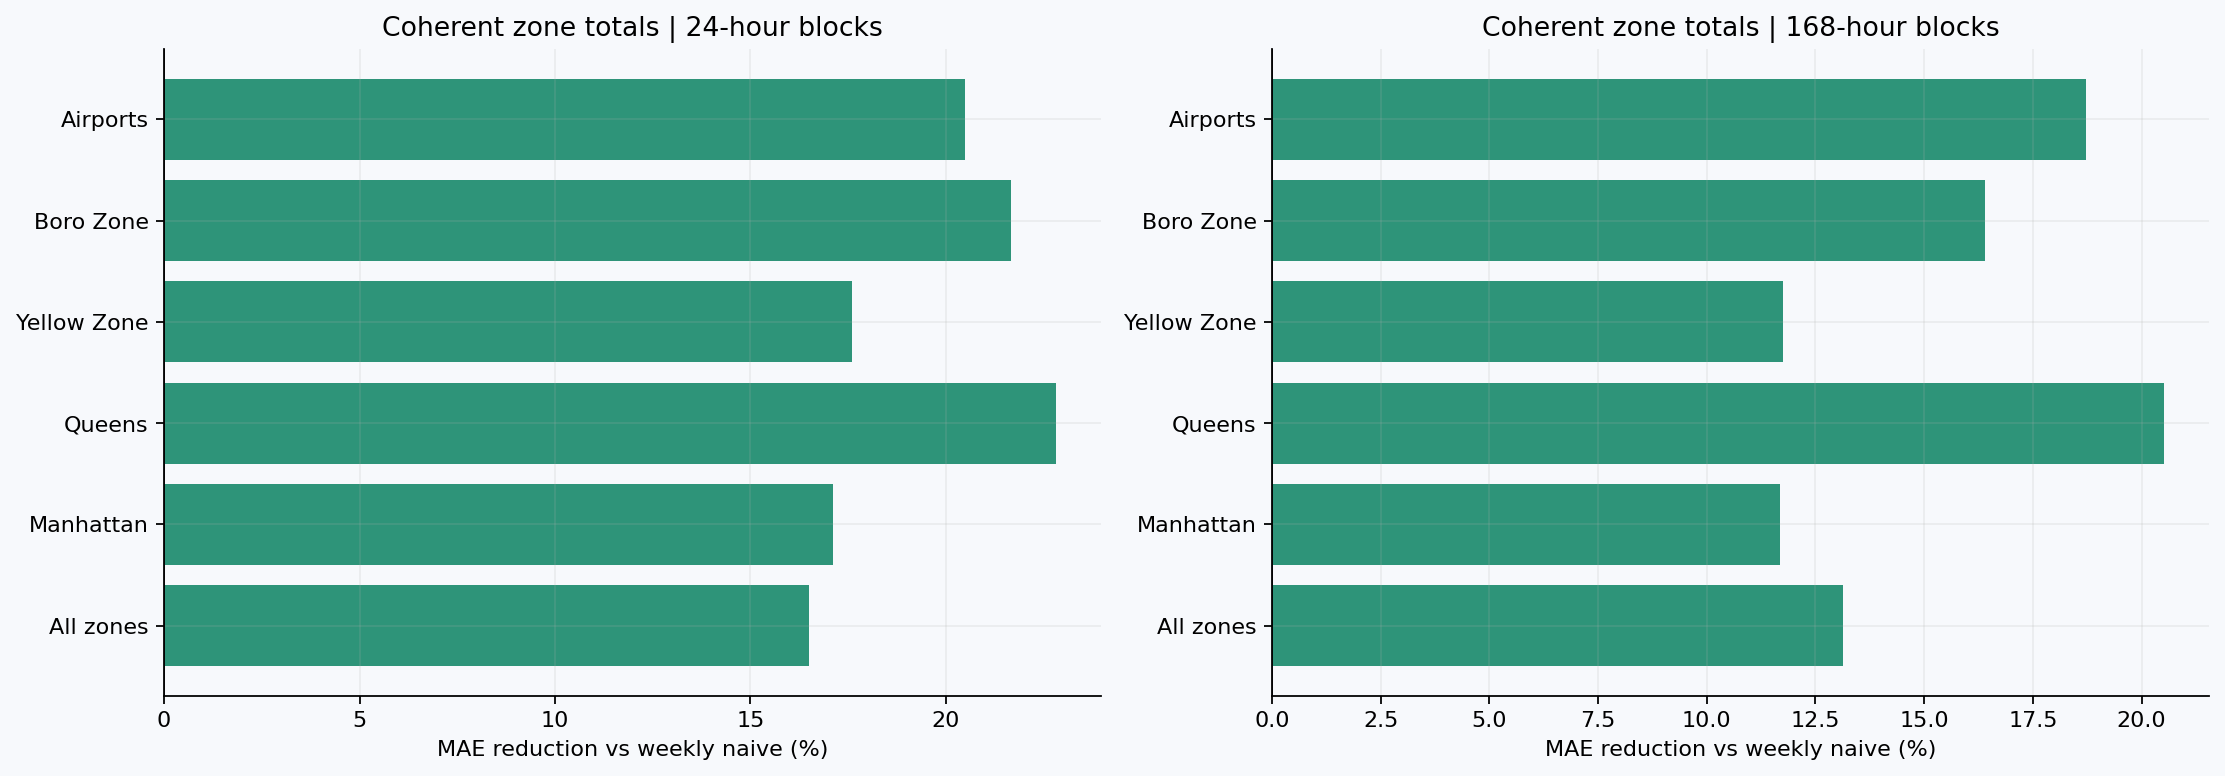

,series_id,schedule,nominal_coverage,coverage,mean_width,interval_score
0,Airports,24,0.800,0.739,166.863,416.912
1,Airports,168,0.800,0.810,190.783,437.289
2,All zones,24,0.800,0.833,"2,015.704","3,725.763"
3,All zones,168,0.800,0.797,"2,346.043","4,776.278"
4,Boro Zone,24,0.800,0.763,202.444,433.465
5,Boro Zone,168,0.800,0.714,196.314,457.485
6,Manhattan,24,0.800,0.844,"1,947.038","3,387.585"
7,Manhattan,168,0.800,0.810,"2,289.372","4,337.179"
8,Queens,24,0.800,0.734,218.104,521.831
9,Queens,168,0.800,0.732,215.797,535.199


In [10]:
figure('13_bottom_up_improvement.png')
display(table('bottom_up_interval_metrics.csv'))

## Daily forecasting and Review 1 context
Daily candidates are seven-day naive, a four-week seasonal mean and daily adaptive seasonal.
No daily ETS or ARIMA is fitted. Scores use complete calendar days and cannot be directly
compared with hourly scores. Review 1 observes recent demand lags and archived weather,
so it answers a different information-availability question.

In [11]:
display(table('daily_test_metrics.csv'))
display(pd.read_csv(ROOT / 'models/modeling/model_comparison_final.csv'))

,series_id,model,selected,n,MAE,RMSE,WAPE,bias,R2,MASE
0,Airports,adaptive_week_daily,True,35,"1,351.593","2,152.397",20.697,232.163,-0.283,1.010
1,Airports,naive_7,False,35,"1,647.314","2,571.270",25.225,221.829,-0.831,1.231
2,All zones,adaptive_week_daily,True,35,"12,774.108","20,147.891",11.453,"4,218.303",0.400,0.877
3,All zones,naive_7,False,35,"14,270.200","23,432.236",12.794,"4,361.629",0.188,0.980
4,Boro Zone,adaptive_week_daily,True,35,"1,310.053","1,671.705",14.282,-104.307,0.097,1.250
5,Boro Zone,naive_7,False,35,"1,720.457","1,958.662",18.756,-36.686,-0.239,1.642
6,Manhattan,adaptive_week_daily,True,35,"12,036.117","18,155.938",11.908,"4,065.118",0.458,0.847
7,Manhattan,naive_7,False,35,"13,116.371","21,117.638",12.977,"4,219.629",0.267,0.923
8,Queens,adaptive_week_daily,True,35,"1,589.331","2,448.239",15.196,122.741,-0.199,1.100
9,Queens,naive_7,False,35,"2,201.314","3,039.011",21.048,142.000,-0.847,1.524


,model,MAE,RMSE,R2
0,Naive 168-hour baseline,9.307,24.057,0.878
1,Model 1 - Linear Regression,7.486,15.704,0.948
2,Model 2 - Random Forest,6.799,15.259,0.951
3,Model 3 - HistGradientBoosting,5.784,13.163,0.963


## Historical forecast example
The 1-7 March 2026 export is issued immediately after the final observed hour.
It is unscored historical extrapolation, not a current live forecast. Prediction intervals
use historical pre-test calibration and may not transfer to a different demand regime.

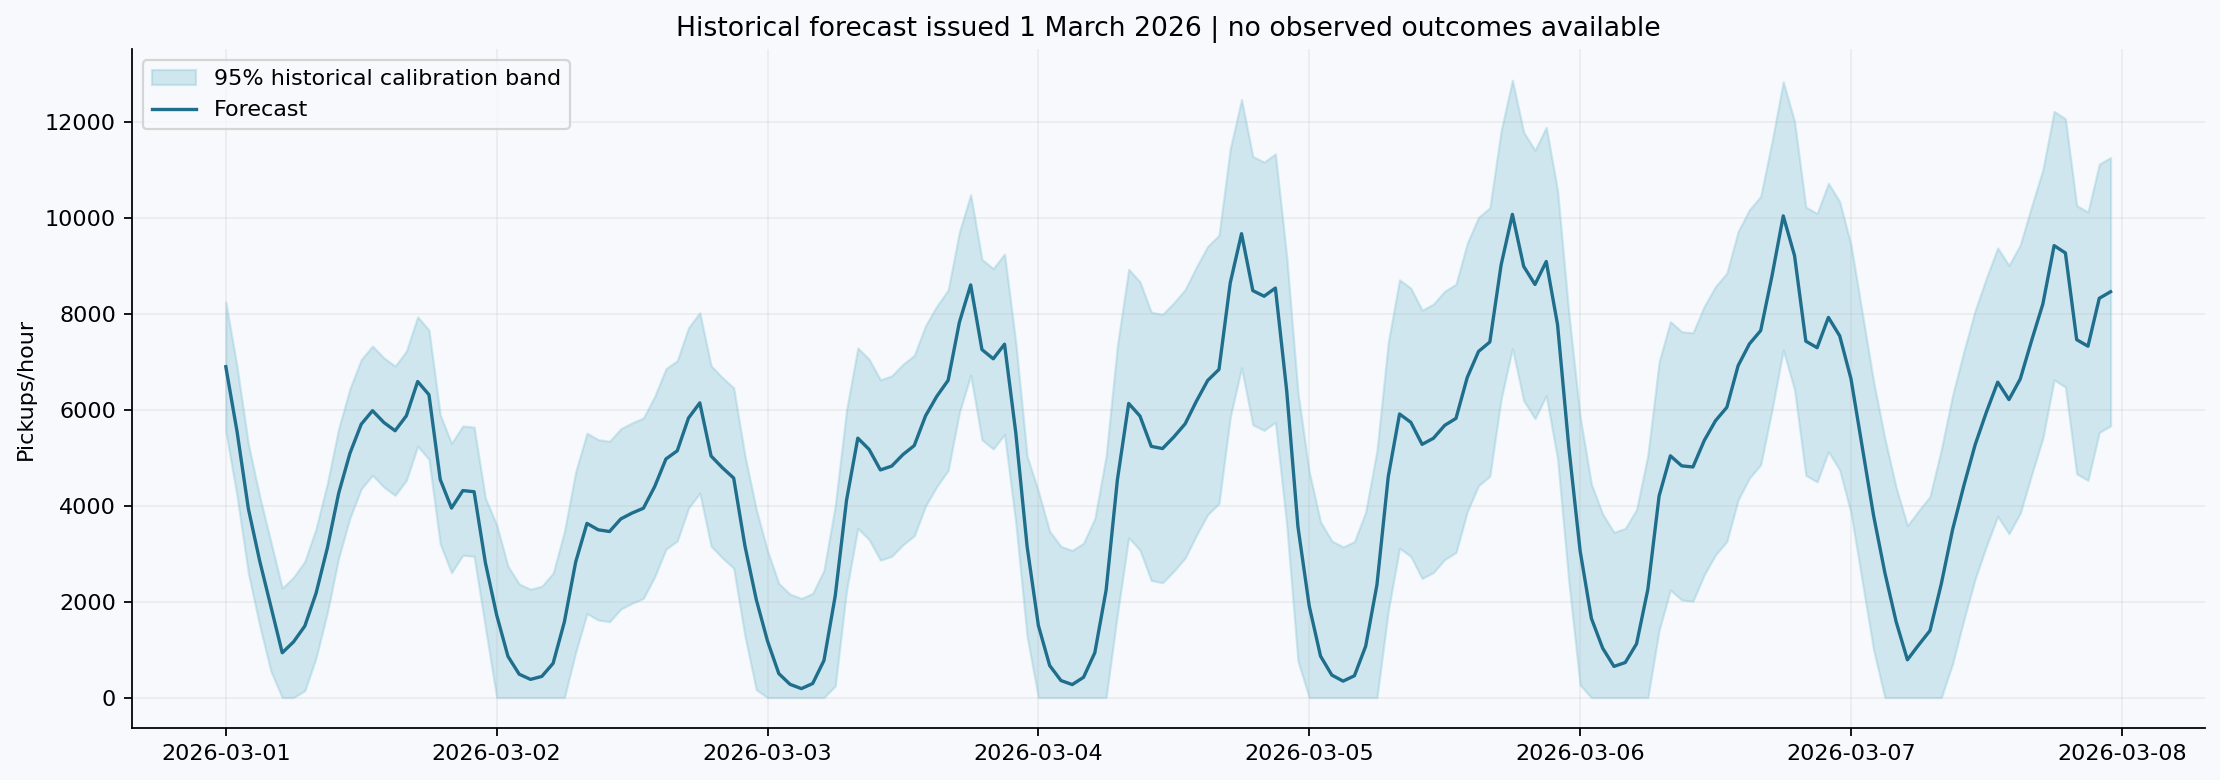

,ds,series_id,model,origin,prediction,lead,bucket,lower_80,upper_80,lower_95,upper_95
0,2026-03-01 00:00:00,All zones,adaptive_week,2026-03-01,"6,898.150",1,001-024,"6,056.793","7,739.506","5,551.267","8,245.033"
1,2026-03-01 01:00:00,All zones,adaptive_week,2026-03-01,"5,540.581",2,001-024,"4,699.224","6,381.937","4,193.698","6,887.464"
2,2026-03-01 02:00:00,All zones,adaptive_week,2026-03-01,"3,937.193",3,001-024,"3,095.836","4,778.549","2,590.310","5,284.076"
3,2026-03-01 03:00:00,All zones,adaptive_week,2026-03-01,"2,852.007",4,001-024,"2,010.651","3,693.364","1,505.124","4,198.890"
4,2026-03-01 04:00:00,All zones,adaptive_week,2026-03-01,"1,892.359",5,001-024,"1,051.003","2,733.716",545.476,"3,239.242"
5,2026-03-01 05:00:00,All zones,adaptive_week,2026-03-01,934.285,6,001-024,92.929,"1,775.642",0.000,"2,281.168"
6,2026-03-01 06:00:00,All zones,adaptive_week,2026-03-01,"1,161.427",7,001-024,320.070,"2,002.783",0.000,"2,508.310"
7,2026-03-01 07:00:00,All zones,adaptive_week,2026-03-01,"1,491.204",8,001-024,649.847,"2,332.560",144.321,"2,838.087"
8,2026-03-01 08:00:00,All zones,adaptive_week,2026-03-01,"2,178.207",9,001-024,"1,336.851","3,019.564",831.324,"3,525.090"
9,2026-03-01 09:00:00,All zones,adaptive_week,2026-03-01,"3,121.197",10,001-024,"2,279.840","3,962.553","1,774.314","4,468.080"


In [12]:
figure('12_next_week_forecast.png')
display(table('aggregate_forecast_next_week.csv').query("series_id == 'All zones'").head(24))

## Validation and limitations
The pipeline verifies that retired model names cannot reappear in saved predictions,
that forecasting functions ignore future targets/weather/Fourier columns.
Forecast diagnostics and figures are saved in the tables and figures folders.

Six months cannot identify annual seasonality. Few holidays, two calibration weeks,
five weekly test origins and winter-specific demand shocks limit generalization.
A fresh holdout, longer data coverage and vintage weather forecasts would improve
the next evaluation. Do not claim universal superiority or infer fleet size directly
from pickup forecasts.

Methods: [rolling-origin evaluation](https://otexts.com/fpp3/tscv.html).
TSB: Teunter, Syntetos and Babai (2011), European Journal of Operational Research 214(3), 606-615.

In [13]:
display(table('output_checks.csv').groupby('passed').size().rename('checks'))

passed
True    234
Name: checks, dtype: int64